# Exploratory data analysis of METABRIC breast cancer data

**PRDL / MLLB — machine learning project**

The regression task estimates **tumour size in millimetres**. The classification task uses **size ≤20 mm versus size >20 mm**. These labels describe size; they are not risk categories or complete cancer stages.

The EDA checks data quality, missingness, distributions and relationships before modelling. It does not establish causality or validate a clinical tool. For the proposed main model, inputs should describe the initial tumour assessment, excluding treatment and subsequent follow-up. The timing of individual clinical measurements still needs checking before making any real-time clinical claim.

**Source:** [clinical METABRIC data on Kaggle](https://www.kaggle.com/datasets/gunesevitan/breast-cancer-metabric), distributed from [cBioPortal](https://www.cbioportal.org/study/summary?id=brca_metabric). The download date is not the date of data collection.

The original CSV is preserved. The existing cleaning rules remove selected columns and patients, but do not impute missing values or automatically remove statistical outliers. Results are displayed in this notebook; there is no automatic figure or table export. Run cells from top to bottom. Dependencies: pandas, NumPy, Matplotlib, Seaborn, SciPy and IPython.


## 1. Shared data preparation and exploration

Start with the original population so that missingness and the effects of filtering remain visible. Data availability is part of the description of the sample, not just a technical problem to hide before plotting.


In [64]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats


In [65]:
df= pd.read_csv("data/Breast Cancer METABRIC.csv")
df

,Patient ID,Age at Diagnosis,Type of Breast Surgery,Cancer Type,Cancer Type Detailed,Cellularity,Chemotherapy,Pam50 + Claudin-low subtype,Cohort,ER status measured by IHC,...,Overall Survival Status,PR Status,Radio Therapy,Relapse Free Status (Months),Relapse Free Status,Sex,3-Gene classifier subtype,Tumor Size,Tumor Stage,Patient's Vital Status
0,MB-0000,75.65,Mastectomy,Breast Cancer,Breast Invasive Ductal Carcinoma,NaN,No,claudin-low,1.0,Positve,...,Living,Negative,Yes,138.65,Not Recurred,Female,ER-/HER2-,22.0,2.0,Living
1,MB-0002,43.19,Breast Conserving,Breast Cancer,Breast Invasive Ductal Carcinoma,High,No,LumA,1.0,Positve,...,Living,Positive,Yes,83.52,Not Recurred,Female,ER+/HER2- High Prolif,10.0,1.0,Living
2,MB-0005,48.87,Mastectomy,Breast Cancer,Breast Invasive Ductal Carcinoma,High,Yes,LumB,1.0,Positve,...,Deceased,Positive,No,151.28,Recurred,Female,NaN,15.0,2.0,Died of Disease
3,MB-0006,47.68,Mastectomy,Breast Cancer,Breast Mixed Ductal and Lobular Carcinoma,Moderate,Yes,LumB,1.0,Positve,...,Living,Positive,Yes,162.76,Not Recurred,Female,NaN,25.0,2.0,Living
4,MB-0008,76.97,Mastectomy,Breast Cancer,Breast Mixed Ductal and Lobular Carcinoma,High,Yes,LumB,1.0,Positve,...,Deceased,Positive,Yes,18.55,Recurred,Female,ER+/HER2- High Prolif,40.0,2.0,Died of Disease
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2504,MTS-T2428,70.05,NaN,Breast Cancer,Invasive Breast Carcinoma,NaN,NaN,NaN,1.0,Positve,...,NaN,NaN,NaN,4.93,Recurred,Female,NaN,27.0,1.0,NaN
2505,MTS-T2429,63.60,NaN,Breast Cancer,Invasive Breast Carcinoma,NaN,NaN,NaN,1.0,Positve,...,NaN,NaN,NaN,16.18,Recurred,Female,NaN,28.0,2.0,NaN
2506,MTS-T2430,NaN,NaN,Breast Cancer,Invasive Breast Carcinoma,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,Female,NaN,NaN,0.0,NaN
2507,MTS-T2431,NaN,NaN,Breast Cancer,Invasive Breast Carcinoma,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,Female,NaN,NaN,0.0,NaN


### Variables and category labels

Inspect the available categories before selecting predictors. Similar-sounding variables may be alternative measurements or encodings of the same information. For example, ER status and ER measured by IHC should not automatically be assumed identical. The raw label `Positve` is a spelling issue to standardise consistently when preparing categorical encodings.

`Sex` is constant in the original data. `Cancer Type` is not fully constant: the initial counts include a few sarcomas, so removing its column is not equivalent to filtering those patients. The current row filters are preserved below. Tumour stage and the Nottingham index are excluded because their definitions can incorporate the size being predicted; the Nottingham index directly contains size in its formula.


In [66]:
# Inspect column names.
name_columns=df.columns.tolist()
print("Columns:", name_columns)

# Inspect categories before choosing encodings or merging variables.
categorical_cols = df.select_dtypes(include=['object', 'category', 'string']).columns.drop("Patient ID")

for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False).rename_axis(None))

Columns: ['Patient ID', 'Age at Diagnosis', 'Type of Breast Surgery', 'Cancer Type', 'Cancer Type Detailed', 'Cellularity', 'Chemotherapy', 'Pam50 + Claudin-low subtype', 'Cohort', 'ER status measured by IHC', 'ER Status', 'Neoplasm Histologic Grade', 'HER2 status measured by SNP6', 'HER2 Status', 'Tumor Other Histologic Subtype', 'Hormone Therapy', 'Inferred Menopausal State', 'Integrative Cluster', 'Primary Tumor Laterality', 'Lymph nodes examined positive', 'Mutation Count', 'Nottingham prognostic index', 'Oncotree Code', 'Overall Survival (Months)', 'Overall Survival Status', 'PR Status', 'Radio Therapy', 'Relapse Free Status (Months)', 'Relapse Free Status', 'Sex', '3-Gene classifier subtype', 'Tumor Size', 'Tumor Stage', "Patient's Vital Status"]

Type of Breast Surgery:
Mastectomy           1170
Breast Conserving     785
NaN                   554
Name: count, dtype: int64

Cancer Type:
Breast Cancer     2506
Breast Sarcoma       3
Name: count, dtype: int64

Cancer Type Detailed:

In [67]:
# Keep the existing column exclusions; the rationale is explained above.
df=df.drop(["Sex"],axis=1)
df=df.drop(["Cancer Type","Tumor Stage",'Nottingham prognostic index'],axis=1)


### Missing values and patient filtering

Patients without an observed regression target are excluded; targets are not imputed. The current rule then removes patients with **more than 50% missing values across the remaining dataframe columns**. The code below preserves that rule exactly.

This percentage includes the ID, the target and follow-up variables, so it is not yet a predictor-only completeness rule. The later audit compares it with a rule based on the proposed inputs. The 50% threshold is a working choice, not a universal statistical standard. Filtering may change the population and should be justified in the report.


In [68]:
# Measure missingness before applying the patient filters.
missing_table = pd.DataFrame({
    'NaN Values': df.isnull().sum(),
    'Non-NaN Values': df.notnull().sum(),
    'NaN Percentage (%)': (df.isnull().mean() * 100).round(2)
})

missing_table = missing_table.sort_values(
    by='NaN Values',
    ascending=False
)

missing_table

,NaN Values,Non-NaN Values,NaN Percentage (%)
3-Gene classifier subtype,745,1764,29.69
Primary Tumor Laterality,639,1870,25.47
Cellularity,592,1917,23.60
Type of Breast Surgery,554,1955,22.08
Chemotherapy,529,1980,21.08
HER2 Status,529,1980,21.08
Integrative Cluster,529,1980,21.08
PR Status,529,1980,21.08
Patient's Vital Status,529,1980,21.08
Radio Therapy,529,1980,21.08


In [69]:
# Inspect completeness at patient level.
features = df.drop(columns=['Patient ID'], errors='ignore')

print("Patients completely empty:", features.isnull().all(axis=1).sum())

Patients completely empty: 0


In [70]:
# Remove patients whose observed target is unavailable; do not impute labels. 
print("Missing Tumor Size:", df['Tumor Size'].isnull().sum())

patients_without_tumor_size=df[df['Tumor Size'].isnull()]["Patient ID"].tolist()
df=df.set_index(["Patient ID"])
df=df.drop(patients_without_tumor_size).reset_index()


Missing Tumor Size: 149


In [71]:
# Inspect completeness at patient level.
missing_patients = pd.DataFrame({
    'Patient ID': df['Patient ID'],
    'NaN Values': df.isnull().sum(axis=1),
    'Non-NaN Values': df.notnull().sum(axis=1),
    'NaN Percentage (%)': (df.isnull().mean(axis=1) * 100).round(2)
})

missing_patients = missing_patients.sort_values(
    by='NaN Values',
    ascending=False
)

missing_patients['Missing Columns'] = df.apply(
    lambda row: row.index[row.isnull()].tolist(),
    axis=1
)

missing_patients[missing_patients["NaN Percentage (%)"]>50]


,Patient ID,NaN Values,Non-NaN Values,NaN Percentage (%),Missing Columns
1973,MTS-T0073,19,11,63.33,"[Type of Breast Surgery, Cellularity, Chemothe..."
1962,MTS-T0060,19,11,63.33,"[Type of Breast Surgery, Cellularity, Chemothe..."
2138,MTS-T0358,19,11,63.33,"[Type of Breast Surgery, Cellularity, Chemothe..."
1983,MTS-T0084,18,12,60.00,"[Type of Breast Surgery, Cellularity, Chemothe..."
1982,MTS-T0083,18,12,60.00,"[Type of Breast Surgery, Cellularity, Chemothe..."
...,...,...,...,...,...
2333,MTS-T2393,16,14,53.33,"[Type of Breast Surgery, Cellularity, Chemothe..."
2348,MTS-T2416,16,14,53.33,"[Type of Breast Surgery, Cellularity, Chemothe..."
2347,MTS-T2415,16,14,53.33,"[Type of Breast Surgery, Cellularity, Chemothe..."
2346,MTS-T2414,16,14,53.33,"[Type of Breast Surgery, Cellularity, Chemothe..."


In [72]:

features = df.drop(columns=['Patient ID'], errors='ignore')

# Use the same patients and percentage criterion as missing_patients.
missing_pct = missing_patients['NaN Percentage (%)'].reindex(features.index)

patients_many_missing = features[missing_pct > 50]

missing_columns = pd.DataFrame({
    'NaN Values': patients_many_missing.isnull().sum(),
    'NaN Percentage (%)': (
        patients_many_missing.isnull().mean() * 100
    ).round(2)
})

missing_columns = missing_columns.sort_values(
    by='NaN Percentage (%)',
    ascending=False
)

display(missing_columns)

,NaN Values,NaN Percentage (%)
Type of Breast Surgery,405,100.00
Chemotherapy,405,100.00
Cellularity,405,100.00
HER2 status measured by SNP6,405,100.00
Pam50 + Claudin-low subtype,405,100.00
HER2 Status,405,100.00
PR Status,405,100.00
Radio Therapy,405,100.00
Overall Survival (Months),405,100.00
Primary Tumor Laterality,405,100.00


In [73]:
# Preserve the current rule: remove patients with more than 50% missing values.
patients_50_more_empty_ft=missing_patients[missing_patients["NaN Percentage (%)"]>50]["Patient ID"].tolist()
df=df.set_index(["Patient ID"])

df_clean=df.drop(patients_50_more_empty_ft).reset_index()
df_clean

,Patient ID,Age at Diagnosis,Type of Breast Surgery,Cancer Type Detailed,Cellularity,Chemotherapy,Pam50 + Claudin-low subtype,Cohort,ER status measured by IHC,ER Status,...,Oncotree Code,Overall Survival (Months),Overall Survival Status,PR Status,Radio Therapy,Relapse Free Status (Months),Relapse Free Status,3-Gene classifier subtype,Tumor Size,Patient's Vital Status
0,MB-0000,75.65,Mastectomy,Breast Invasive Ductal Carcinoma,NaN,No,claudin-low,1.0,Positve,Positive,...,IDC,140.500000,Living,Negative,Yes,138.65,Not Recurred,ER-/HER2-,22.0,Living
1,MB-0002,43.19,Breast Conserving,Breast Invasive Ductal Carcinoma,High,No,LumA,1.0,Positve,Positive,...,IDC,84.633333,Living,Positive,Yes,83.52,Not Recurred,ER+/HER2- High Prolif,10.0,Living
2,MB-0005,48.87,Mastectomy,Breast Invasive Ductal Carcinoma,High,Yes,LumB,1.0,Positve,Positive,...,IDC,163.700000,Deceased,Positive,No,151.28,Recurred,NaN,15.0,Died of Disease
3,MB-0006,47.68,Mastectomy,Breast Mixed Ductal and Lobular Carcinoma,Moderate,Yes,LumB,1.0,Positve,Positive,...,MDLC,164.933333,Living,Positive,Yes,162.76,Not Recurred,NaN,25.0,Living
4,MB-0008,76.97,Mastectomy,Breast Mixed Ductal and Lobular Carcinoma,High,Yes,LumB,1.0,Positve,Positive,...,MDLC,41.366667,Deceased,Positive,Yes,18.55,Recurred,ER+/HER2- High Prolif,40.0,Died of Disease
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1950,MB-7295,43.10,Breast Conserving,Breast Invasive Lobular Carcinoma,High,No,LumA,4.0,Positve,Positive,...,ILC,196.866667,Living,Positive,Yes,194.28,Not Recurred,ER+/HER2- Low Prolif,25.0,Living
1951,MB-7296,42.88,Mastectomy,Breast Invasive Ductal Carcinoma,High,No,LumB,4.0,Positve,Positive,...,IDC,44.733333,Deceased,Negative,Yes,16.09,Recurred,NaN,20.0,Died of Disease
1952,MB-7297,62.90,Mastectomy,Breast Invasive Ductal Carcinoma,High,No,LumB,4.0,Positve,Positive,...,IDC,175.966667,Deceased,Positive,Yes,121.18,Recurred,NaN,25.0,Died of Disease
1953,MB-7298,61.16,Mastectomy,Breast Invasive Ductal Carcinoma,Moderate,No,LumB,4.0,Positve,Positive,...,IDC,86.233333,Deceased,Positive,No,85.10,Not Recurred,ER+/HER2- High Prolif,25.0,Died of Other Causes


### Proposed predictors and information available at prediction

The main task is a retrospective estimate of tumour size from clinical characteristics and biomarkers, excluding treatment and subsequent outcomes. This is a proposed input set, not a claim that every measurement is available at first presentation. Measurement timing must be confirmed before describing the model as usable at diagnosis.

Histological subtype is kept as one representation; `Cancer Type Detailed` and `Oncotree Code` are excluded from the proposed inputs to avoid repeating closely overlapping information. ER status is preferred over the alternative IHC column for this initial specification; that does not mean the assays are identical. Molecular subtype columns remain candidates, with redundancy to be reviewed on training data.

The table defines modelling roles only. It does **not** delete additional columns from `df_clean` or select features by their performance on the full dataset.


In [74]:
# Proposed inputs, defined separately from the dataframe used for descriptive plots.
predictor_cols = [
    'Age at Diagnosis', 'Cellularity', 'ER Status', 'HER2 Status', 'PR Status',
    'Neoplasm Histologic Grade', 'Tumor Other Histologic Subtype',
    'Lymph nodes examined positive', 'Mutation Count',
    'Pam50 + Claudin-low subtype', '3-Gene classifier subtype',
    'Integrative Cluster', 'Inferred Menopausal State', 'Primary Tumor Laterality'
]

followup_cols = [
    'Overall Survival (Months)', 'Overall Survival Status',
    'Relapse Free Status (Months)', 'Relapse Free Status', "Patient's Vital Status"
]
treatment_cols = ['Type of Breast Surgery', 'Chemotherapy', 'Hormone Therapy', 'Radio Therapy']
alternative_cols = ['Cancer Type Detailed', 'Oncotree Code',
                    'ER status measured by IHC', 'HER2 status measured by SNP6']

roles = []
for col in df_clean.columns:
    if col in predictor_cols:
        decision, reason = 'Candidate input', 'Review timing and redundancy before modelling'
    elif col == 'Tumor Size':
        decision, reason = 'Target only', 'Defines both supervised tasks'
    elif col == 'Patient ID':
        decision, reason = 'Exclude', 'Patient identifier'
    elif col in followup_cols:
        decision, reason = 'Exclude', 'Information from subsequent follow-up'
    elif col in treatment_cols:
        decision, reason = 'Exclude', 'Outside the proposed pre-treatment input set'
    elif col in alternative_cols:
        decision, reason = 'Exclude initially', 'Alternative measurement or overlapping representation'
    else:
        decision, reason = 'Audit separately', 'Cohort describes data grouping, not a tumour measurement'
    roles.append([col, decision, reason])

predictor_decisions = pd.DataFrame(roles, columns=['Variable', 'Proposed role', 'Reason'])
display(predictor_decisions)


,Variable,Proposed role,Reason
0,Patient ID,Exclude,Patient identifier
1,Age at Diagnosis,Candidate input,Review timing and redundancy before modelling
2,Type of Breast Surgery,Exclude,Outside the proposed pre-treatment input set
3,Cancer Type Detailed,Exclude initially,Alternative measurement or overlapping represe...
4,Cellularity,Candidate input,Review timing and redundancy before modelling
5,Chemotherapy,Exclude,Outside the proposed pre-treatment input set
6,Pam50 + Claudin-low subtype,Candidate input,Review timing and redundancy before modelling
7,Cohort,Audit separately,"Cohort describes data grouping, not a tumour m..."
8,ER status measured by IHC,Exclude initially,Alternative measurement or overlapping represe...
9,ER Status,Candidate input,Review timing and redundancy before modelling


### Remaining missing values and a predictor-only filtering audit

This table uses the **final retained sample**, including categorical variables. It describes what would still need handling during modelling. A missing biomarker is not automatically a negative biomarker result.

The existing filter counts all remaining dataframe columns. The audit below instead calculates missingness over the proposed predictors among all patients with known size, before that filter. The same threshold is used: **more than 50% missing**. Comparing retained counts and changed membership shows whether the choice of denominator matters.

This is an audit, not an automatic change to the sample. Finalise the input set and justify the filtering rule before fitting models. Systematic missingness can select particular cohorts or patient profiles. For modelling, median imputation for skewed numerical variables and an explicit unknown category for categorical inputs are initial options to evaluate within training folds; no imputation is performed here.


In [75]:
final_missing = pd.DataFrame({
    'Missing values': df_clean.isna().sum(),
    'Missing (%)': df_clean.isna().mean() * 100,
    'Observed values': df_clean.notna().sum()
}).sort_values('Missing (%)', ascending=False)
display(final_missing.round(2))

# At this point df contains target-known patients before the row-completeness filter.
predictor_missing_pct = df[predictor_cols].isna().mean(axis=1) * 100
predictor_keep = predictor_missing_pct <= 50
current_ids = set(df_clean['Patient ID'])
proposed_ids = set(df.index[predictor_keep])

filter_audit = pd.DataFrame({
    'Rule': ['Current dataframe-wide rule', 'Proposed-predictor rule'],
    'Target-known patients': [len(df), len(df)],
    'Retained patients': [len(current_ids), len(proposed_ids)]
})
display(filter_audit)
print('Retained only by the current rule:', len(current_ids - proposed_ids))
print('Retained only by the predictor rule:', len(proposed_ids - current_ids))


,Missing values,Missing (%),Observed values
3-Gene classifier subtype,212,10.84,1743
Mutation Count,115,5.88,1840
Primary Tumor Laterality,106,5.42,1849
Neoplasm Histologic Grade,79,4.04,1876
Lymph nodes examined positive,70,3.58,1885
Cellularity,61,3.12,1894
Tumor Other Histologic Subtype,39,1.99,1916
ER status measured by IHC,36,1.84,1919
Type of Breast Surgery,18,0.92,1937
Integrative Cluster,1,0.05,1954


,Rule,Target-known patients,Retained patients
0,Current dataframe-wide rule,2360,1955
1,Proposed-predictor rule,2360,1954


Retained only by the current rule: 1
Retained only by the predictor rule: 0


### Distributions in the retained sample

Numerical variables are shown with histograms and boxplots without clipping their extremes. Histological grade and cohort are treated as categories even though they are stored as numbers. Categorical bars show **counts**, including a `Missing` category; they are not percentage plots.

Follow-up durations are described for completeness, but a histogram of observed survival months is not a survival curve: observations may be censored. Follow-up variables are not proposed inputs for predicting initial tumour size.


#### Numerical summary

All statistics use `df_clean`, the same population as the plots. Compare means with medians and quantiles when distributions are skewed. The `missing` column uses the whole retained sample as its denominator; each variable's other statistics use its observed values.


In [76]:
# Select numerical columns
numeric_cols = df_clean.select_dtypes(
    include=['number']
).columns.drop([
    'Patient ID'], errors='ignore')

# Exclude numerical variables that represent categories
categorical_numeric = [
    'Tumor Stage',
    'Neoplasm Histologic Grade',
    "Cohort"
]

numeric_cols = numeric_cols.drop(
    categorical_numeric, errors='ignore'
)

numeric_summary = df_clean[numeric_cols].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).T
numeric_summary["median"] = df_clean[numeric_cols].median()
numeric_summary["skew"] = df_clean[numeric_cols].skew()
numeric_summary["missing"] = df_clean[numeric_cols].isna().mean() * 100
display(numeric_summary.round(3))

,count,mean,std,min,5%,25%,50%,75%,95%,max,median,skew,missing
Age at Diagnosis,1955.0,61.133,12.966,21.93,38.836,51.450,61.880,70.650,81.335,96.29,61.880,-0.207,0.000
Lymph nodes examined positive,1885.0,2.008,4.094,0.00,0.000,0.000,0.000,2.000,10.000,45.00,0.000,3.832,3.581
Mutation Count,1840.0,5.665,3.684,1.00,1.000,3.000,5.000,7.000,12.000,46.00,5.000,2.563,5.882
Overall Survival (Months),1955.0,125.111,75.748,0.10,19.330,60.883,116.433,184.783,259.943,351.00,116.433,0.369,0.000
Relapse Free Status (Months),1955.0,109.945,76.142,0.00,10.902,41.760,100.720,166.895,251.670,346.38,100.720,0.482,0.000
Tumor Size,1955.0,26.276,15.380,1.00,11.000,17.000,23.000,30.000,52.000,182.00,23.000,3.216,0.000


#### Histograms and categorical counts

Histograms show overall shape and long tails. The KDE line is only a smoothed visual guide; for discrete counts such as positive nodes, the integer-valued bars are more directly interpretable. Categorical labels are wrapped only for display so that different categories are never merged.


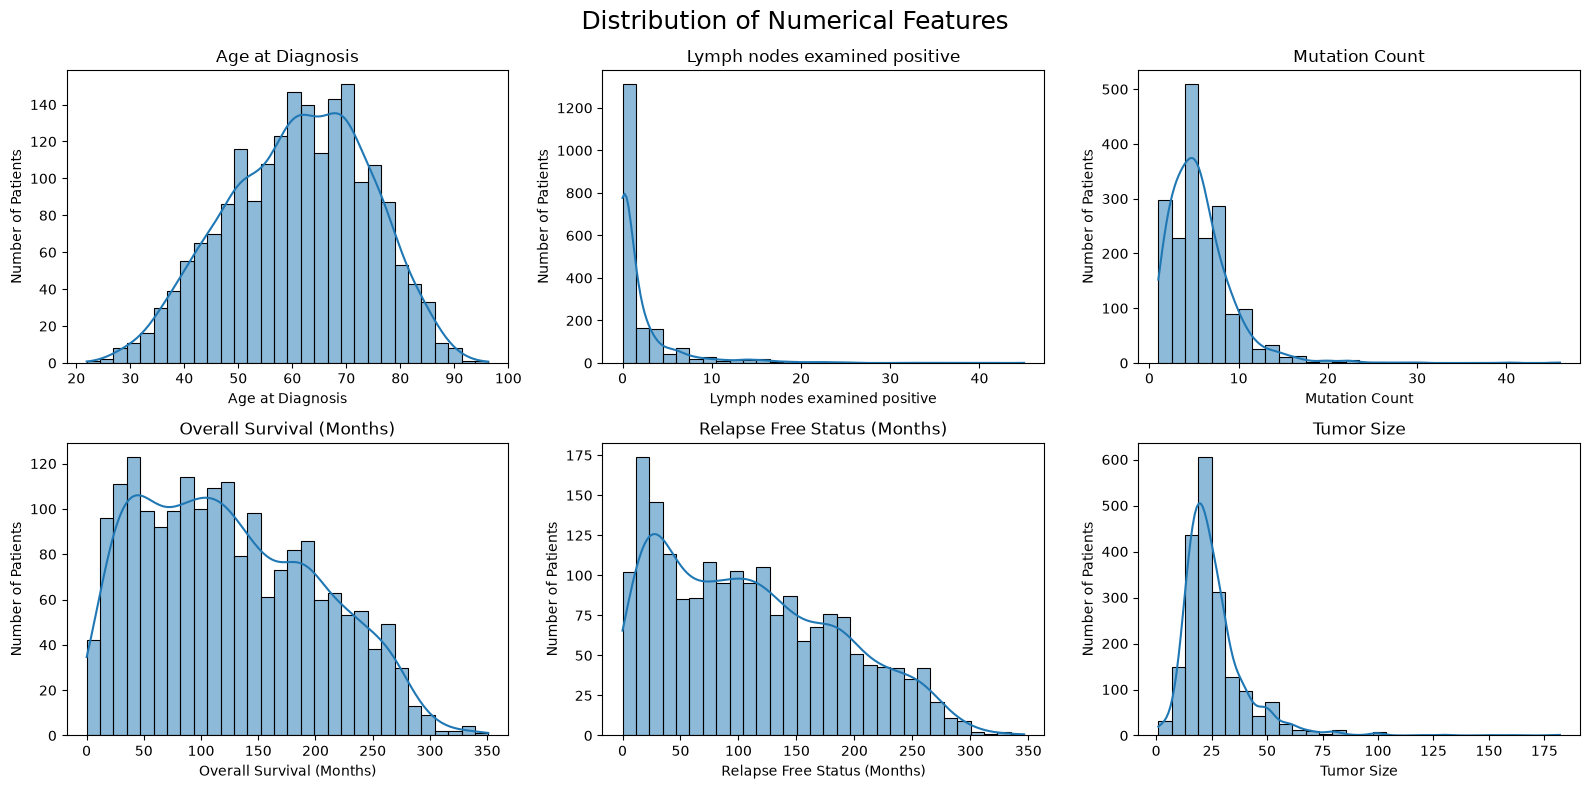

In [77]:
# Create histograms
ncols = 3
nrows = (len(numeric_cols) + ncols - 1) // ncols

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(16, 4 * nrows)
)

axes = np.array(axes).flatten()

for i, col in enumerate(numeric_cols):

    sns.histplot(
        data=df_clean,
        x=col,
        bins=30,
        kde=True,
        ax=axes[i]
    )

    axes[i].set_title(col)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Number of Patients')

for j in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Distribution of Numerical Features', fontsize=18)
plt.tight_layout()
plt.show()

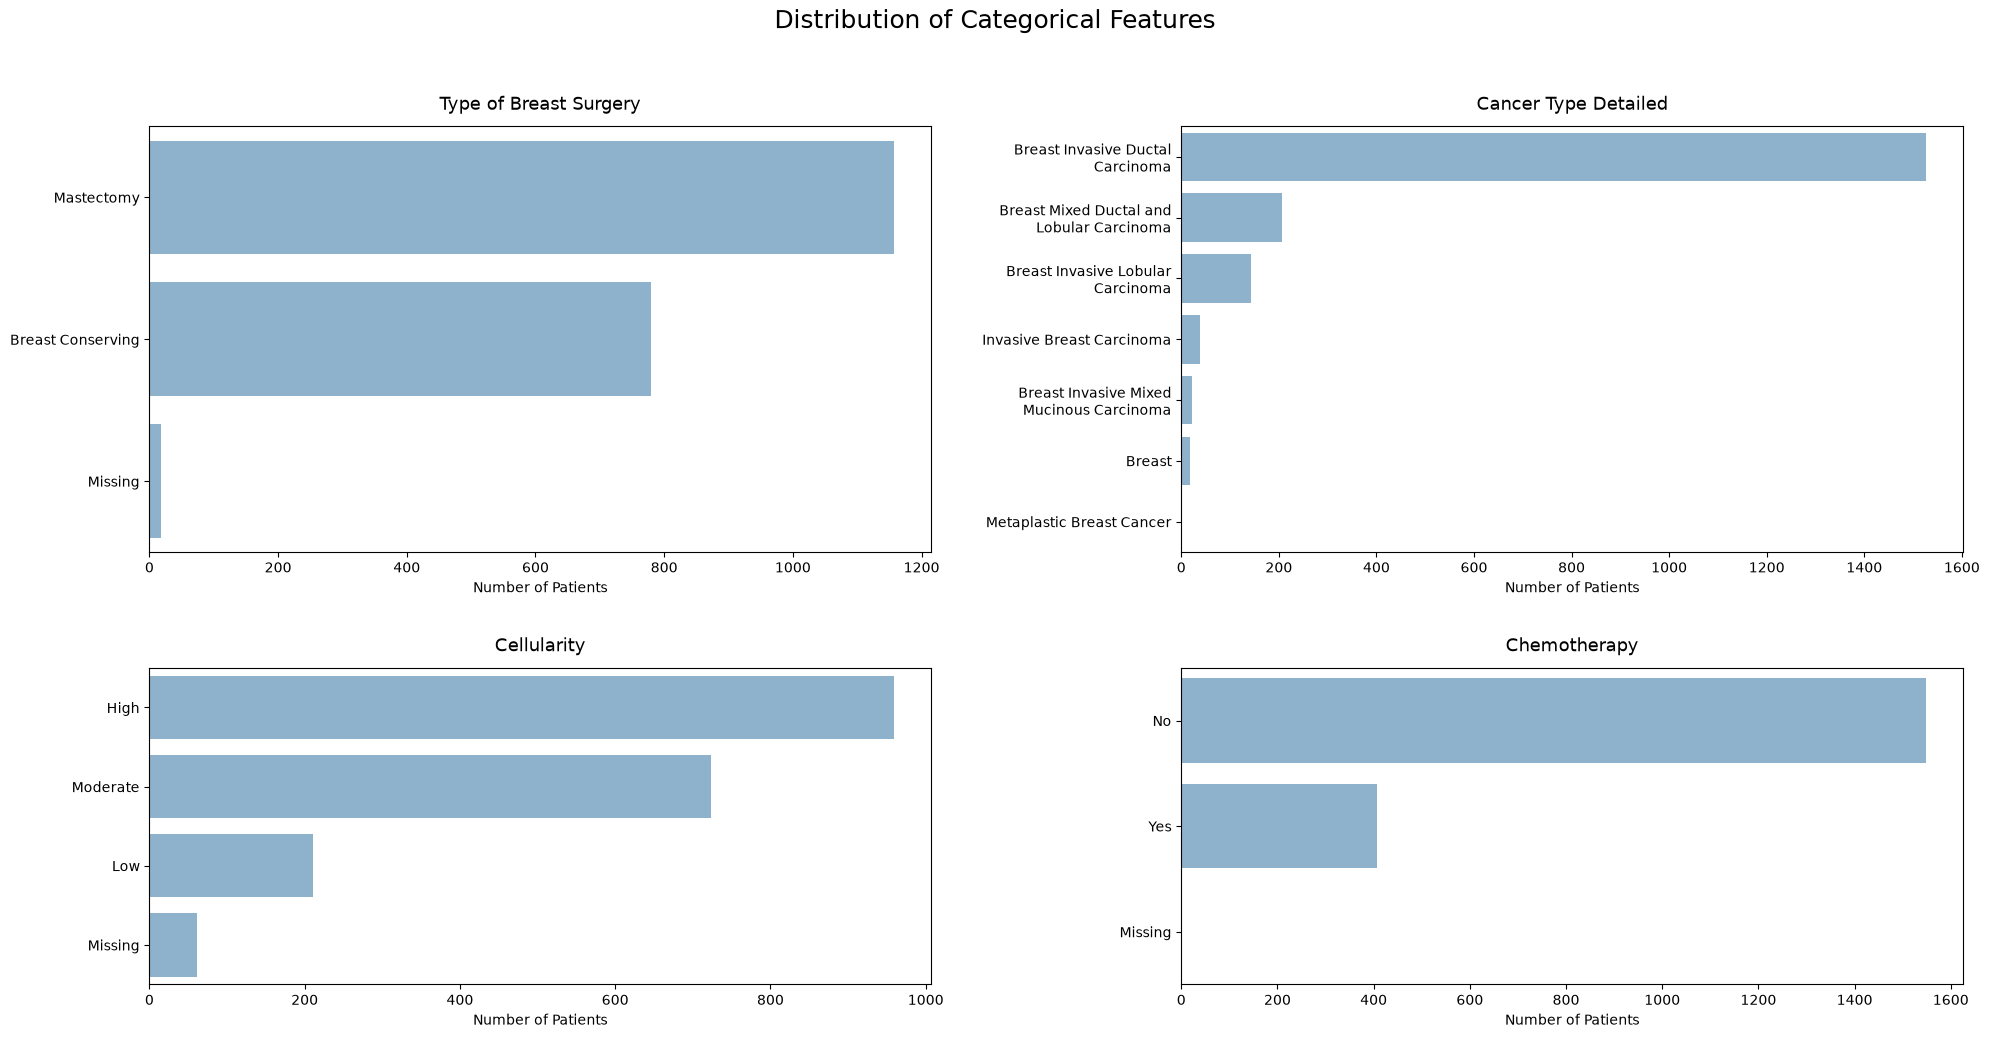

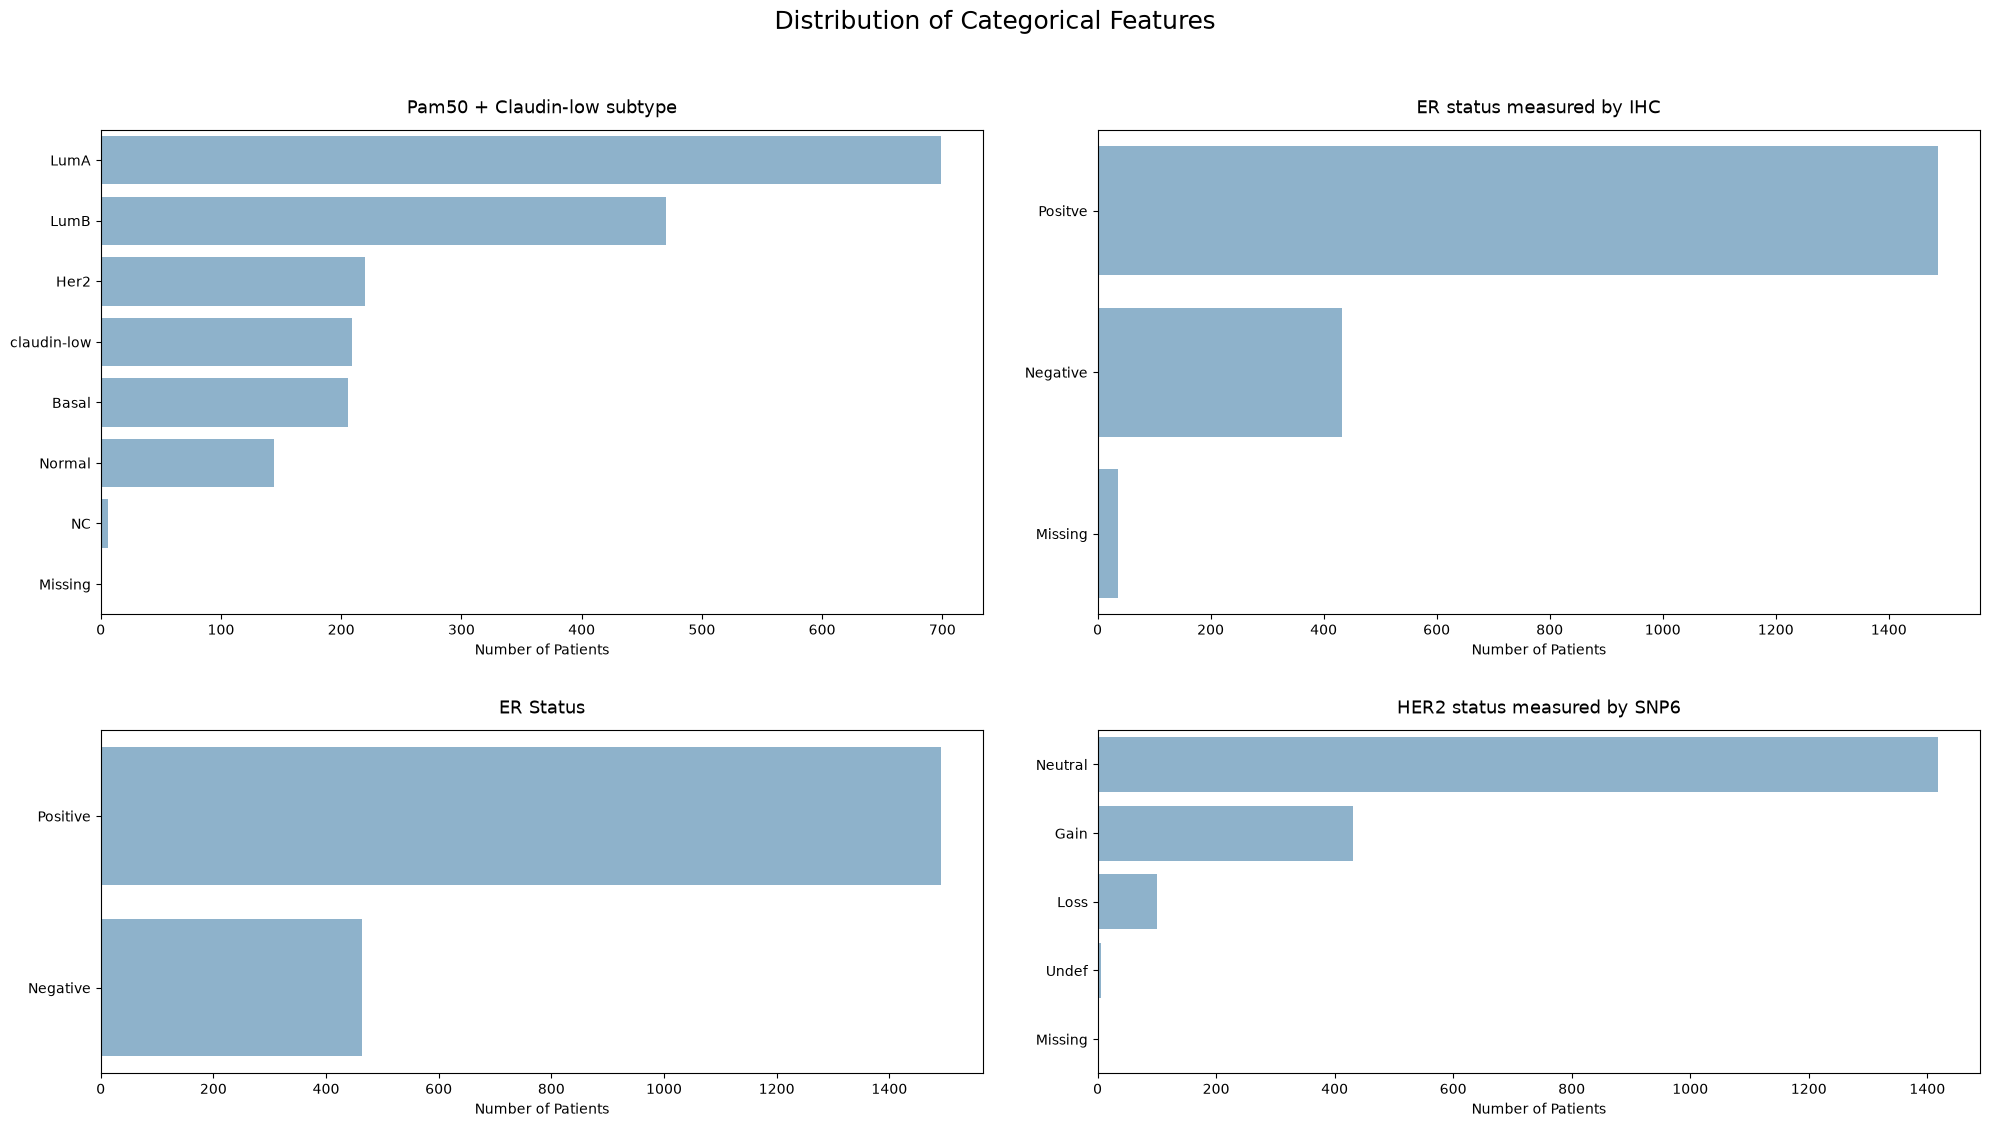

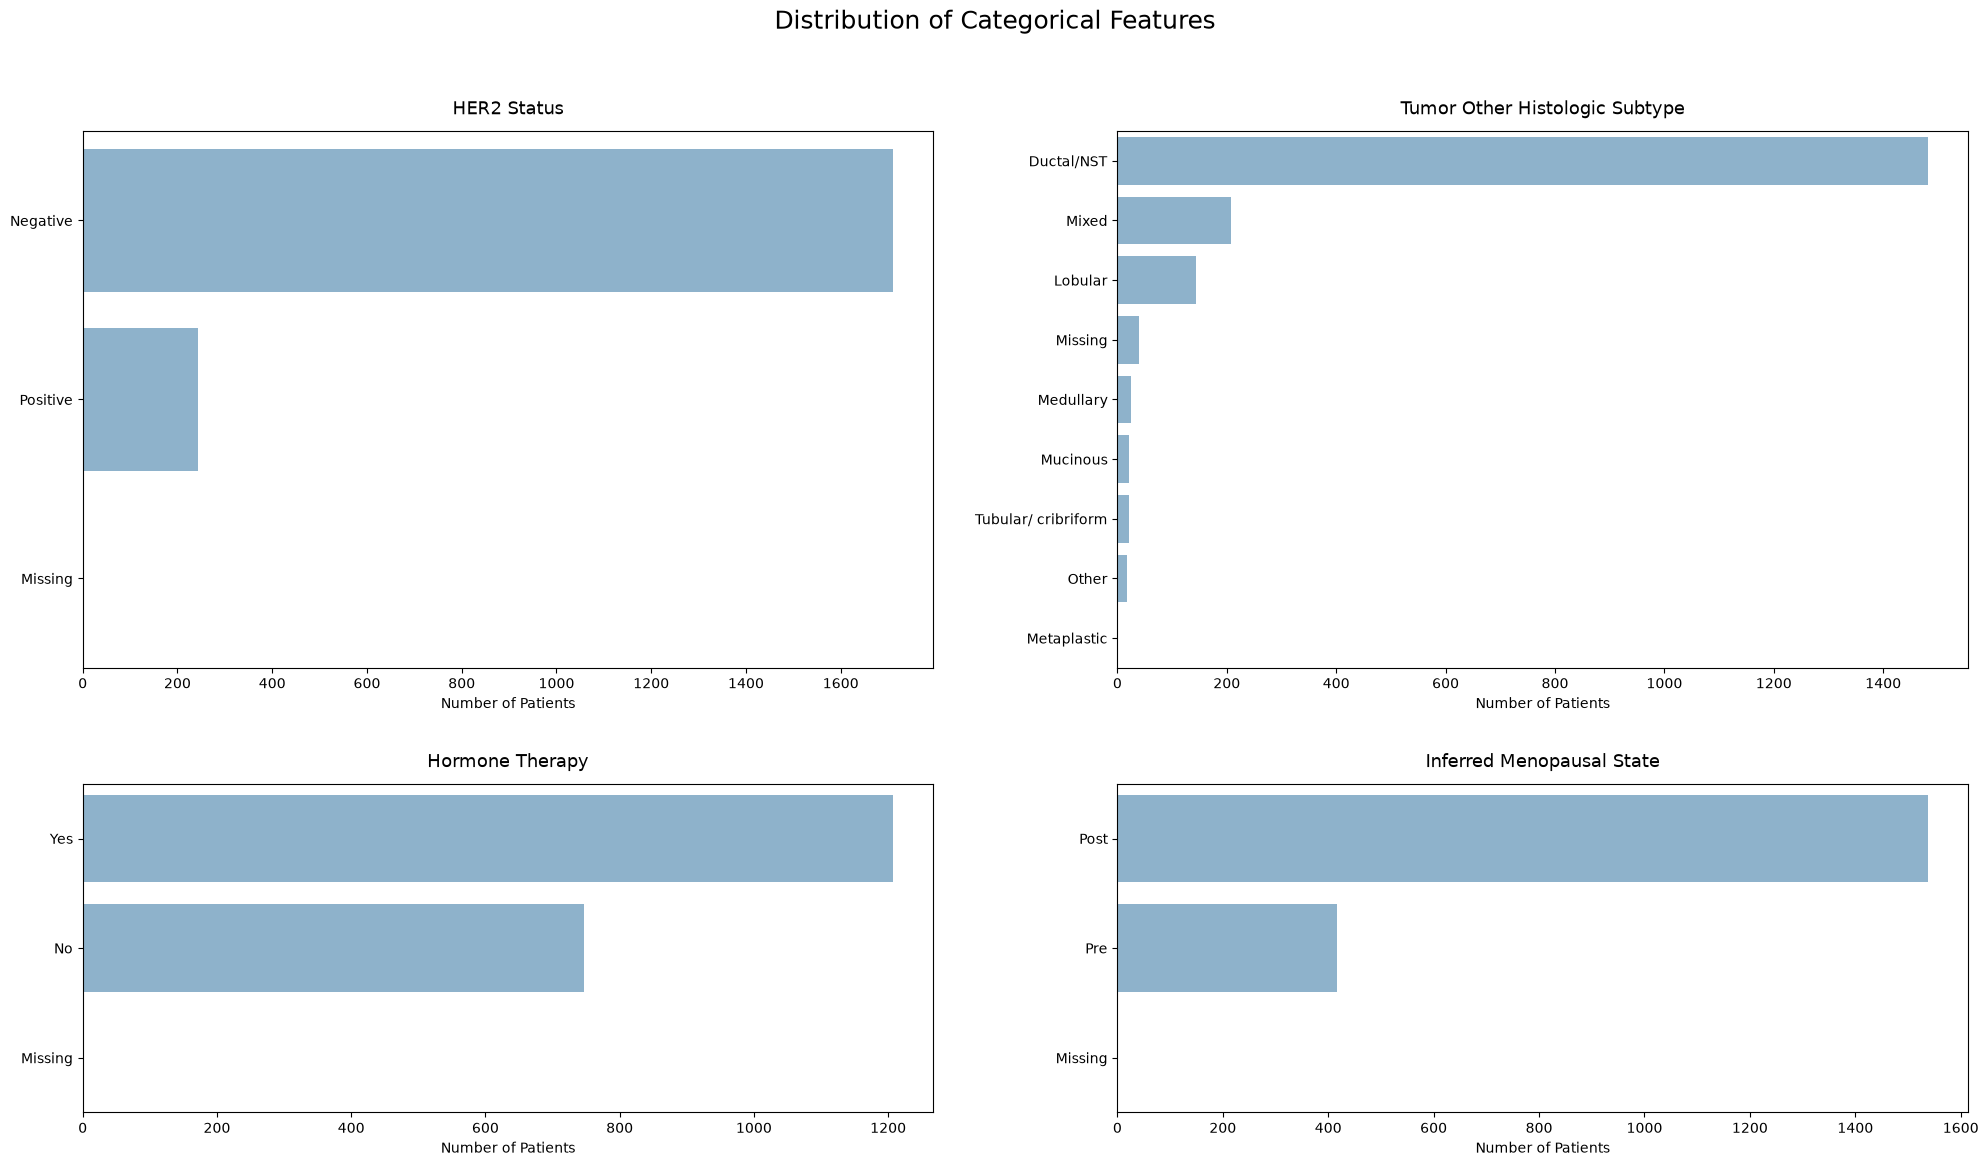

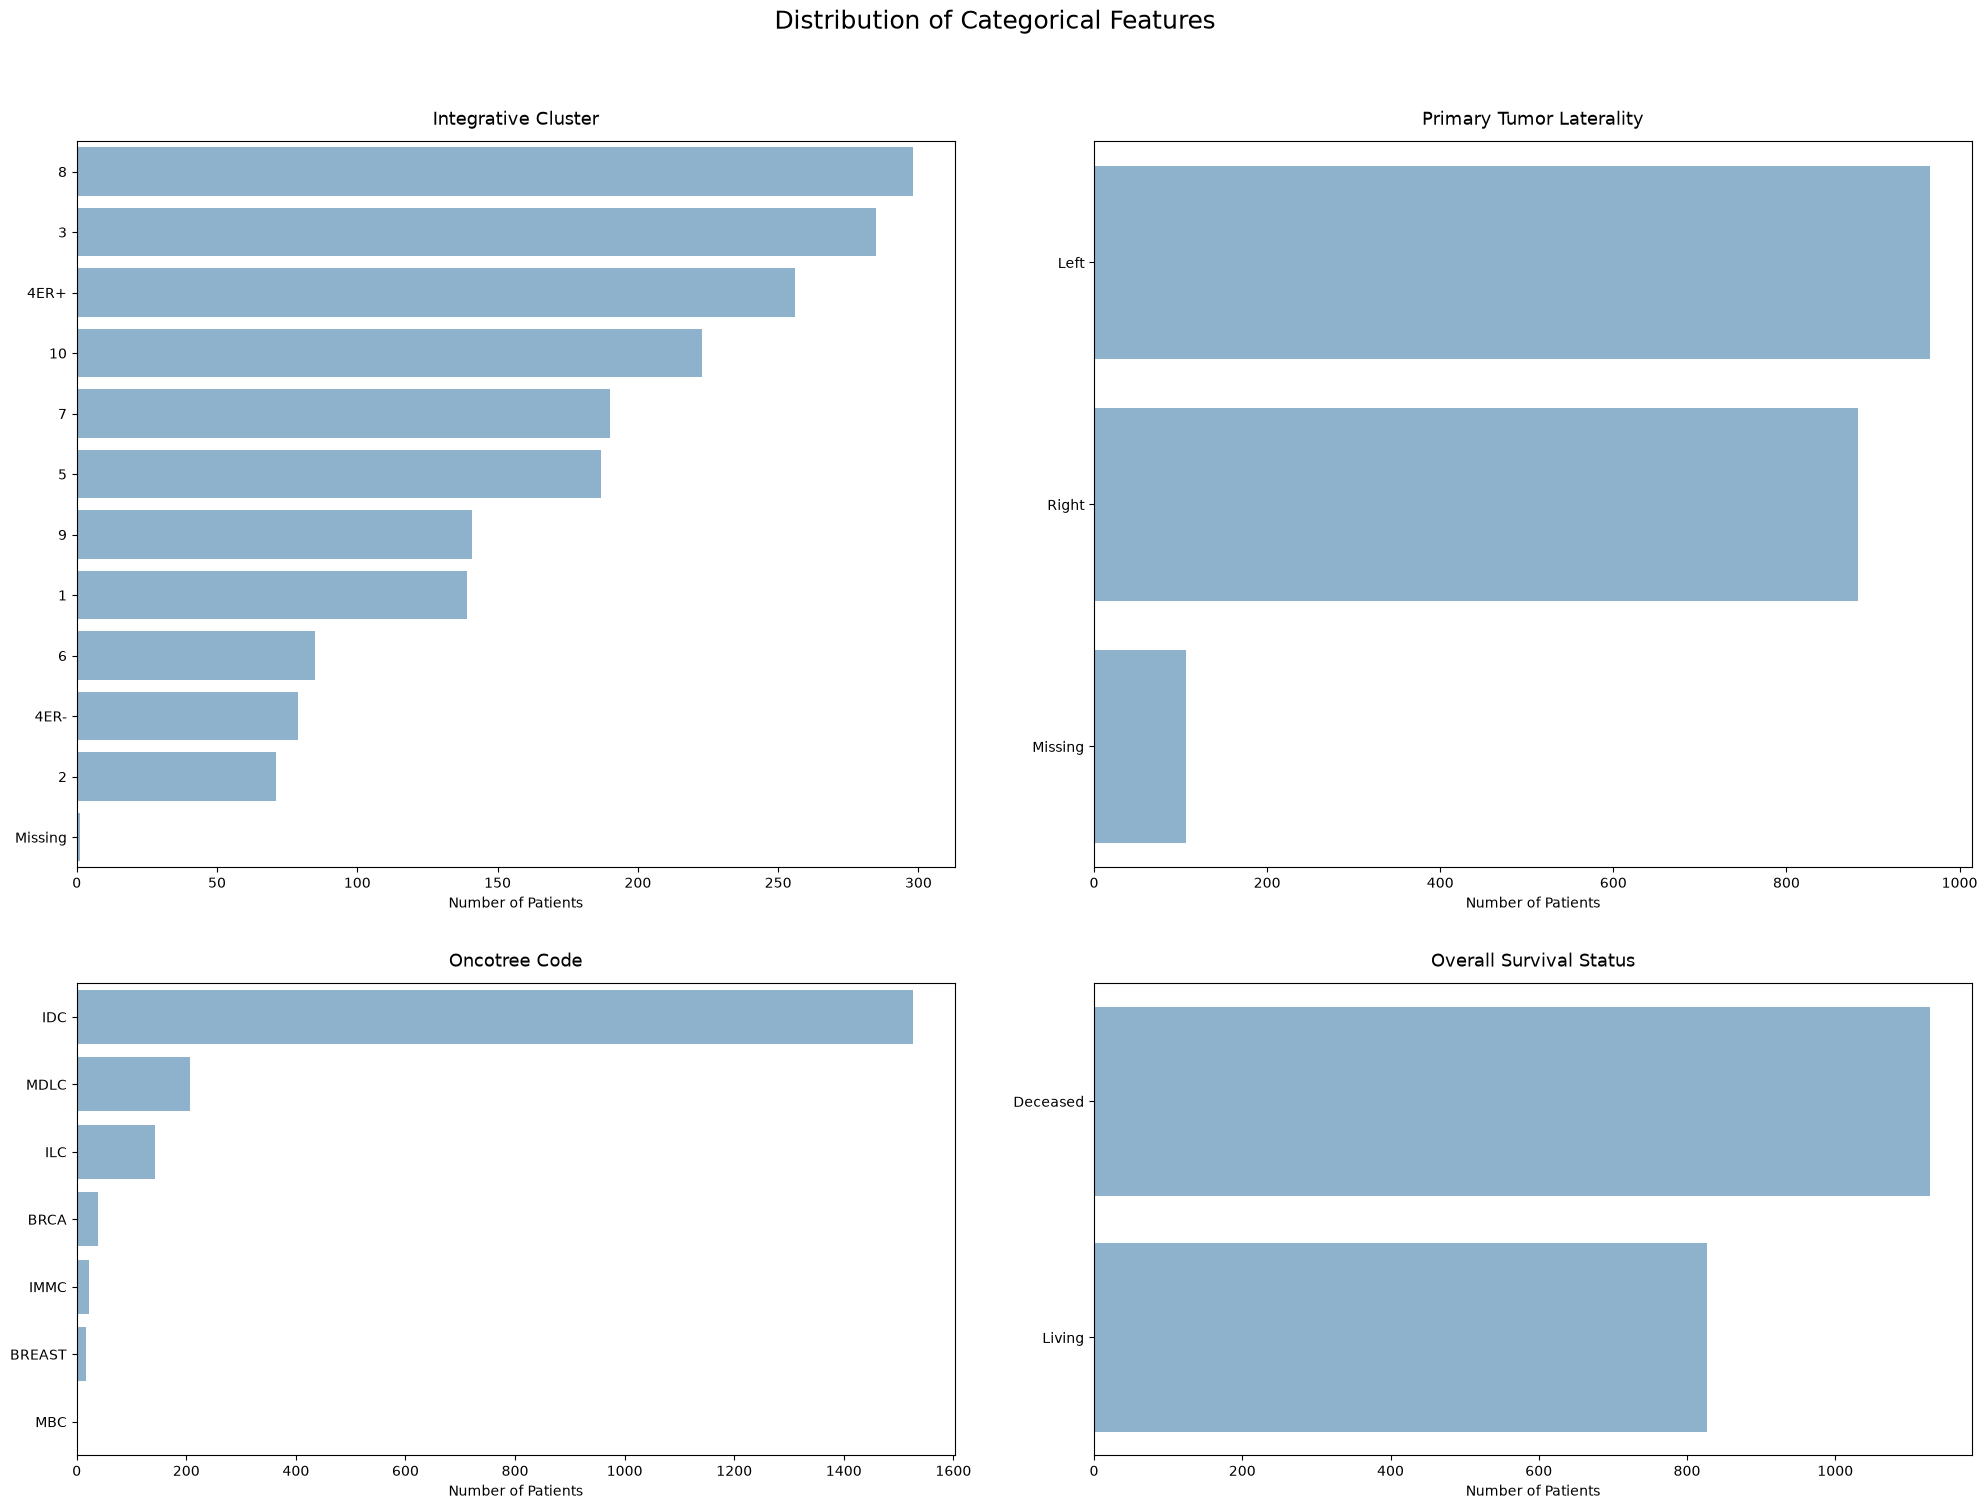

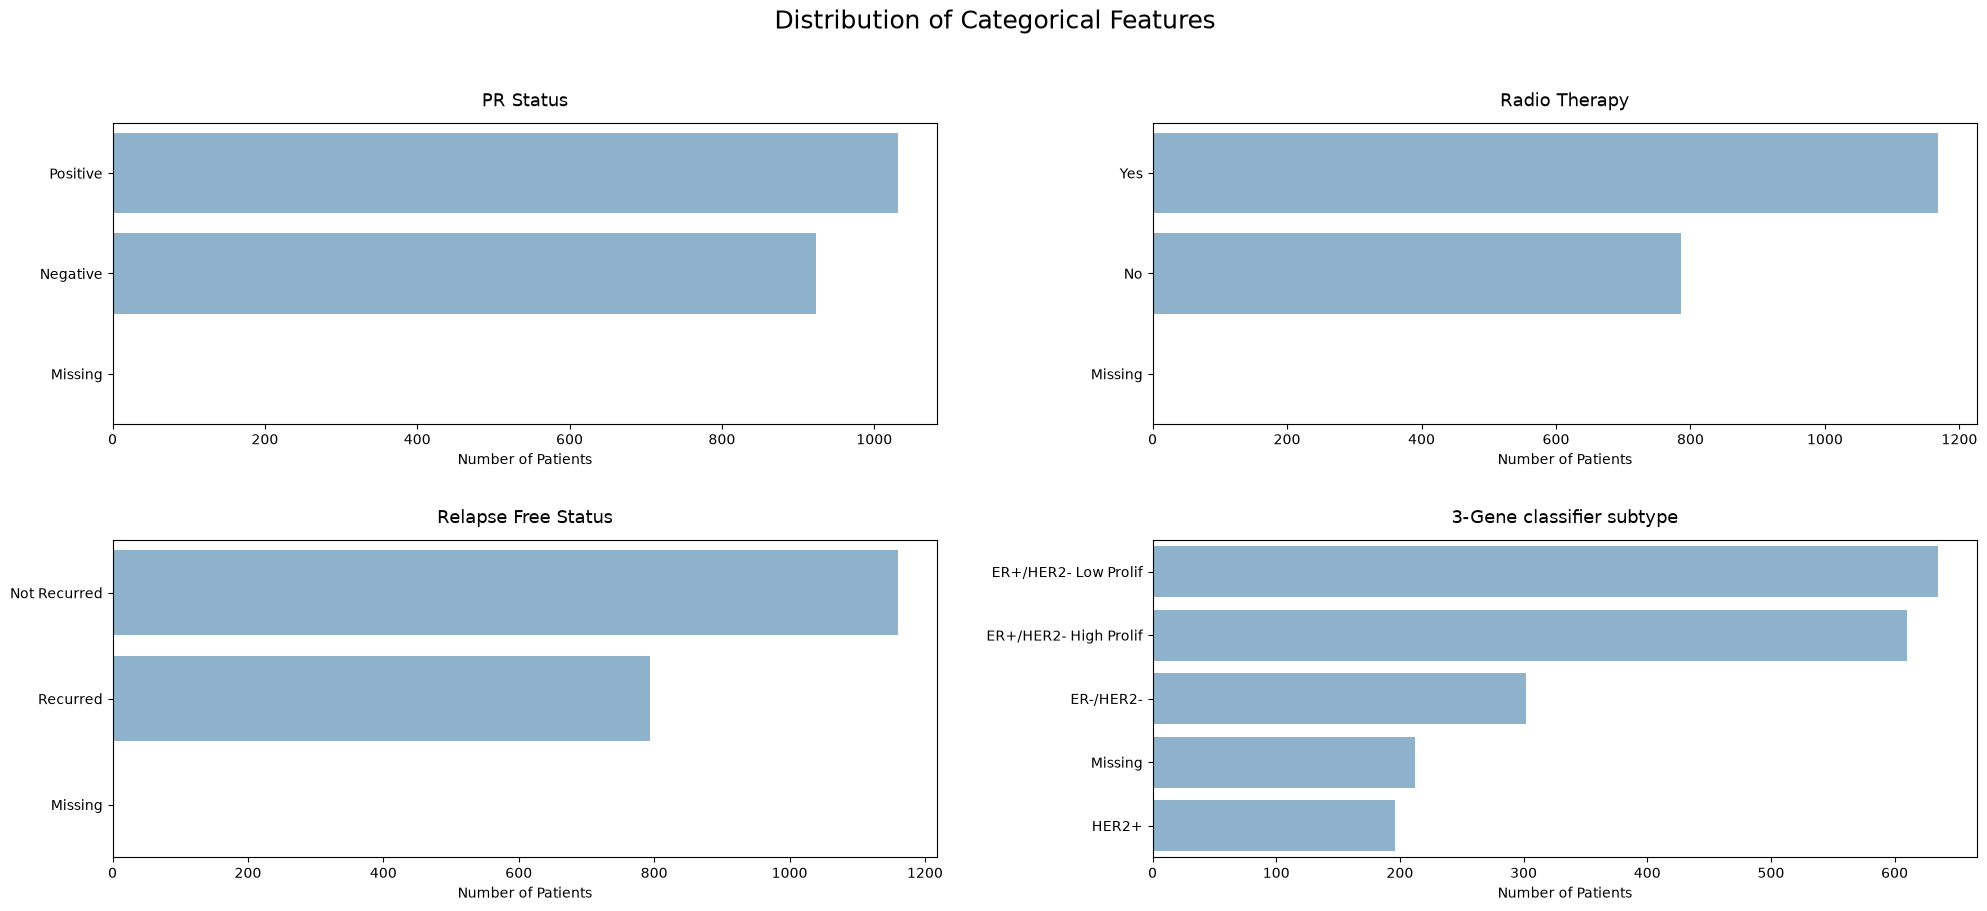

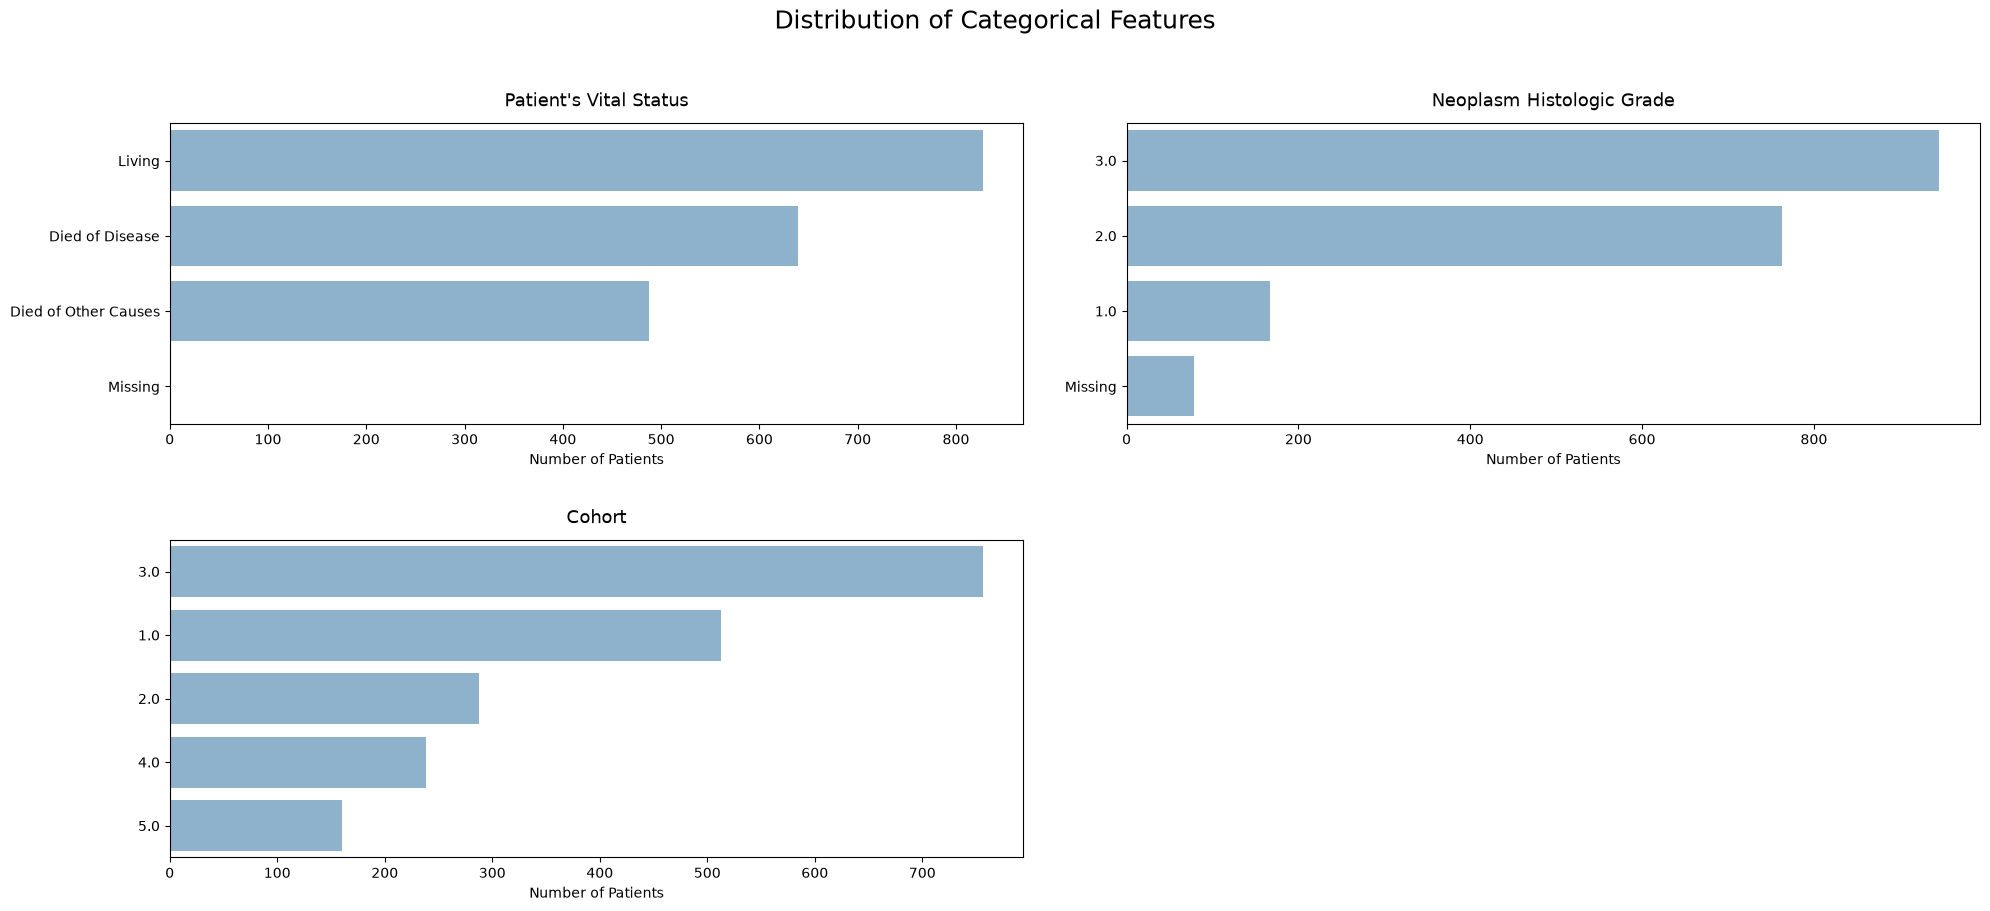

In [78]:
# Select categorical columns
import textwrap

categorical_cols = df_clean.select_dtypes(
    include=['object', 'category', 'string', 'bool']
).columns.drop('Patient ID', errors='ignore')

categorical_cols = list(categorical_cols) + [
    col for col in categorical_numeric if col in df_clean.columns
]

# Four plots per figure, with horizontal bars for long category names.
ncols = 2
for start in range(0, len(categorical_cols), 4):
    columns = categorical_cols[start:start + 4]
    nrows = (len(columns) + ncols - 1) // ncols
    row_heights = [
        max(4.5, 1.5 + 0.65 * max(
            df_clean[col].nunique(dropna=False)
            for col in columns[row * ncols:(row + 1) * ncols]
        ))
        for row in range(nrows)
    ]

    fig, axes = plt.subplots(
        nrows, ncols, figsize=(20, sum(row_heights)),
        gridspec_kw={'height_ratios': row_heights}, squeeze=False
    )
    axes = np.array(axes).flatten()

    for i, col in enumerate(columns):
        counts = (
            df_clean[col]
            .astype('string')
            .fillna('Missing')
            .value_counts()
        )

        # Plot distinct categories; wrap only the displayed labels.
        sns.barplot(
            x=counts.values,
            y=counts.index.tolist(),
            order=counts.index.tolist(),
            orient='h',
            color='#1f77b4',
            alpha=0.55,
            ax=axes[i]
        )
        axes[i].set_yticks(range(len(counts)))
        axes[i].set_yticklabels([
            textwrap.fill(str(label), width=28) for label in counts.index
        ])
        axes[i].set_title(col, fontsize=13, pad=12)
        axes[i].set_xlabel('Number of Patients', fontsize=10)
        axes[i].set_ylabel('')
        axes[i].tick_params(axis='both', labelsize=10)

    for j in range(len(columns), len(axes)):
        fig.delaxes(axes[j])

    plt.suptitle('Distribution of Categorical Features', fontsize=18)
    plt.tight_layout(h_pad=3, w_pad=3, rect=[0, 0, 1, 0.95])
    plt.show()


#### Numerical boxplots for the full sample

These boxplots summarise the numerical variables across all retained patients. The box contains the central 50% of observed values, and the line inside it marks the median. Points outside the whiskers are potential statistical outliers and should not be assumed to be errors.


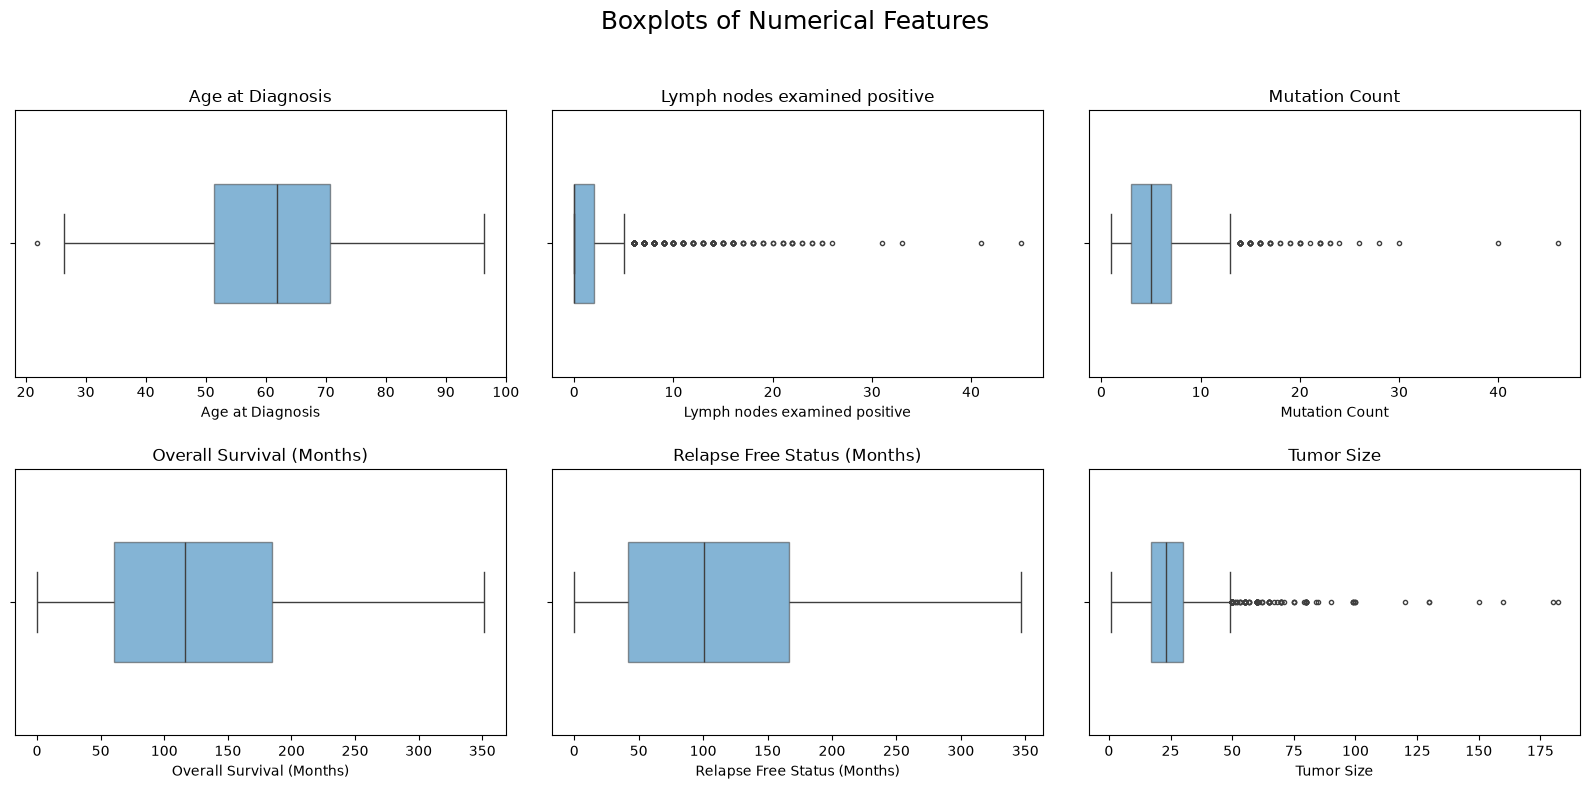

In [79]:
ncols = 3
nrows = max(1, (len(numeric_cols) + ncols - 1) // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4 * nrows))
axes = np.array(axes).flatten()

for i, col in enumerate(numeric_cols):
    sns.boxplot(
        data=df_clean, x=col, color='#1f77b4', saturation=1,
        width=0.45, linewidth=1, fliersize=3,
        boxprops={'alpha': 0.55}, ax=axes[i]
    )
    axes[i].set_title(col)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('')

for j in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Boxplots of Numerical Features', fontsize=18)
plt.tight_layout(h_pad=2, w_pad=2, rect=[0, 0, 1, 0.95])
plt.show()


### Duplicates, unexpected values and statistical outliers

Check the retained sample for duplicate rows, duplicate IDs, negative numerical values and unexpected grade codes. Negative values are flagged for review, not automatically corrected. Positive values can also be implausible: the reported minima and maxima should be assessed using the variable definitions and units.

The IQR rule identifies values outside Q1 − 1.5 × IQR and Q3 + 1.5 × IQR. Percentages use **observed values** as their denominator. Skewed clinical counts can produce many flagged patients without any data-entry error. No patient is removed in this section.


In [80]:
print('Duplicated rows:', df_clean.duplicated().sum())
print('Duplicated Patient IDs:', df_clean['Patient ID'].duplicated().sum())

outlier_rows = []
for col in numeric_cols:
    values = df_clean[col].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    extreme = (values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)
    outlier_rows.append([
        col, len(values), values.min(), values.max(),
        (values < 0).sum(), extreme.sum(), extreme.mean() * 100
    ])

outlier_summary = pd.DataFrame(outlier_rows, columns=[
    'Variable', 'Observed values', 'Min', 'Max',
    'Negative values', 'IQR outliers', 'IQR outliers (%)'
])
display(outlier_summary.round(2))

grade = df_clean['Neoplasm Histologic Grade'].dropna()
print('Unexpected grades:', grade[~grade.isin([1, 2, 3])].unique())


Duplicated rows: 0
Duplicated Patient IDs: 0


,Variable,Observed values,Min,Max,Negative values,IQR outliers,IQR outliers (%)
0,Age at Diagnosis,1955,21.93,96.29,0,1,0.05
1,Lymph nodes examined positive,1885,0.00,45.00,0,209,11.09
2,Mutation Count,1840,1.00,46.00,0,61,3.32
3,Overall Survival (Months),1955,0.10,351.00,0,0,0.00
4,Relapse Free Status (Months),1955,0.00,346.38,0,0,0.00
5,Tumor Size,1955,1.00,182.00,0,151,7.72


Unexpected grades: []


### Variables used in both focused comparisons

Age, positive lymph nodes and mutation count are used in the regression scatter plots and the classification summary. The separate classification figure also includes all numerical variables.


In [81]:
class_features = ['Age at Diagnosis', 'Lymph nodes examined positive', 'Mutation Count']


### Shared findings

- The existing cleaning retains **1955 patients**. There are no duplicate rows or duplicate patient IDs in this retained sample. This does not prove that the selected population represents the full original dataset.
- IQR flags are retained for review. A patient can be statistically extreme and still be valid; no outlier removal is justified merely by appearing outside the whiskers.
- The current missingness filter counts all remaining dataframe columns. The predictor-only audit retains **1954 patients**, compared with **1955** under the current rule. The audit has not changed the sample. Finalise predictors and the completeness criterion before modelling, and assess which cohorts or patient profiles are lost.


## 2. EDA for regression

The target is **tumour size in millimetres**. The following plots and associations use the measured size directly, without grouping patients into size classes.


### Scatter plots against tumour size

Each point is a patient with both values available. The plots complement correlation coefficients by revealing the form of the relationship, concentrations of observations and extreme values. Vertical bands in node and mutation counts are expected because those variables are integers. A small individual correlation does not rule out nonlinear or joint predictive information.


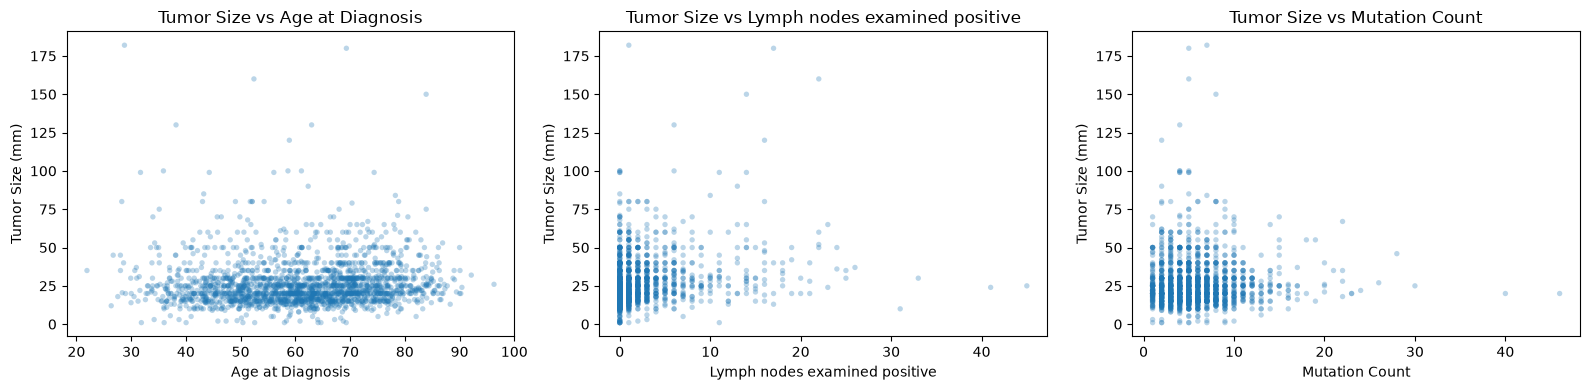

In [82]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, col in zip(axes, class_features):
    plot_data = df_clean[[col, 'Tumor Size']].dropna()
    ax.scatter(
        plot_data[col], plot_data['Tumor Size'],
        color='#1f77b4', alpha=0.3, s=15, edgecolors='none'
    )
    ax.set_title(f'Tumor Size vs {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Tumor Size (mm)')

plt.tight_layout()
plt.show()


### Tumour size across categorical groups

These boxplots compare the continuous target across the levels of each categorical variable. Check the group sizes before interpreting rare categories. Comparisons involving treatment and follow-up are descriptive and do not establish treatment effects.


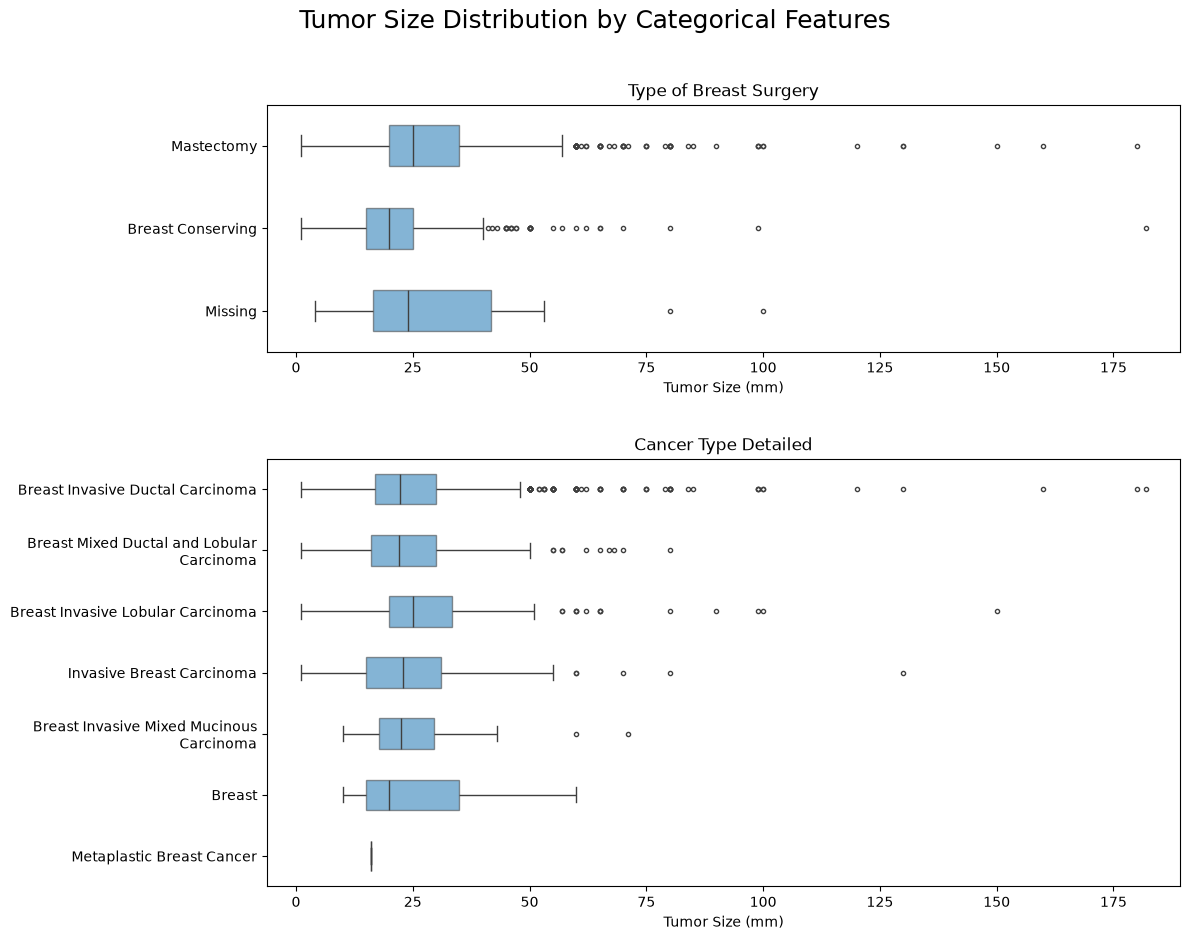

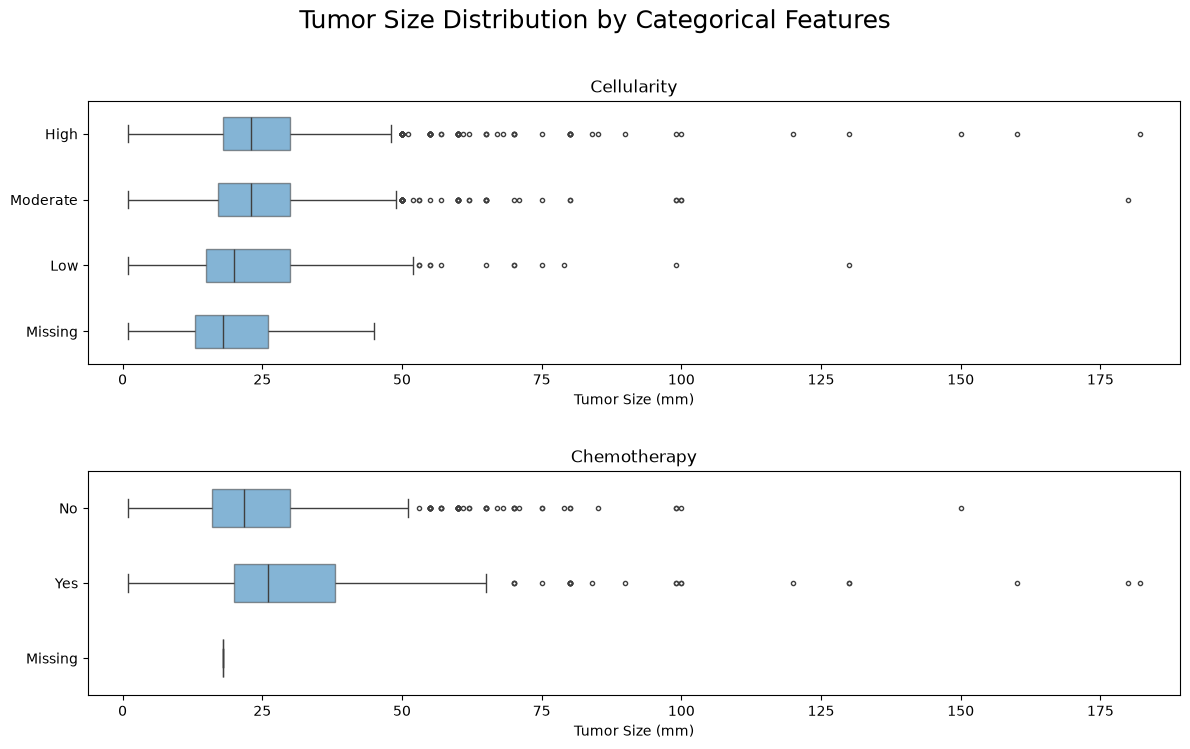

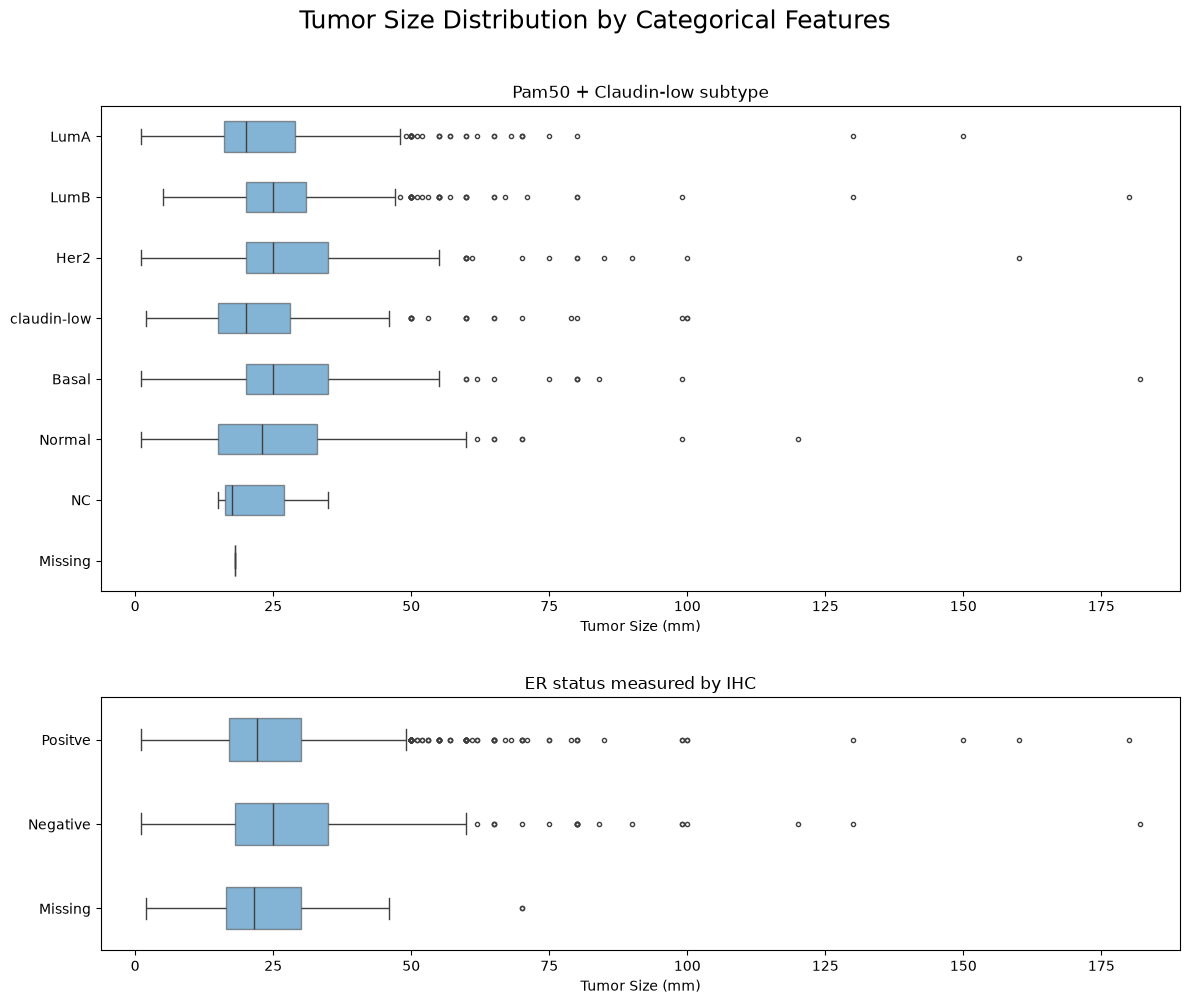

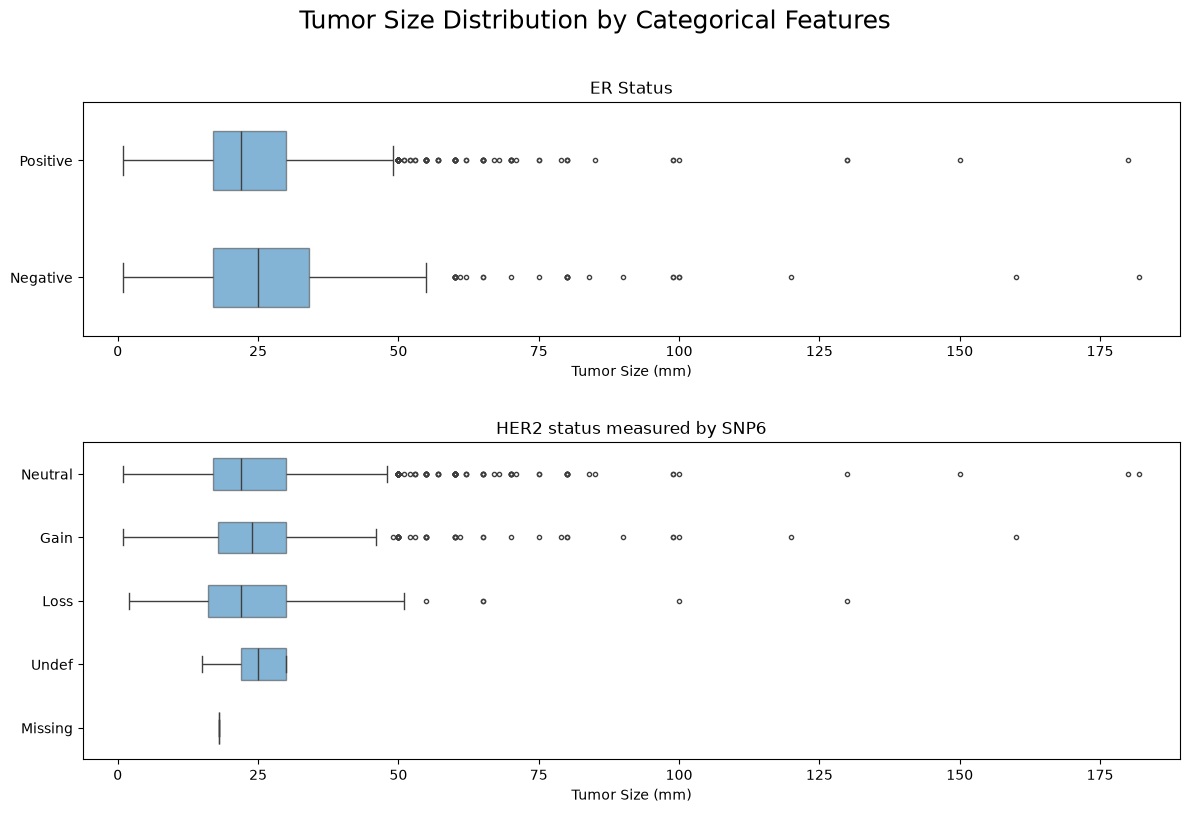

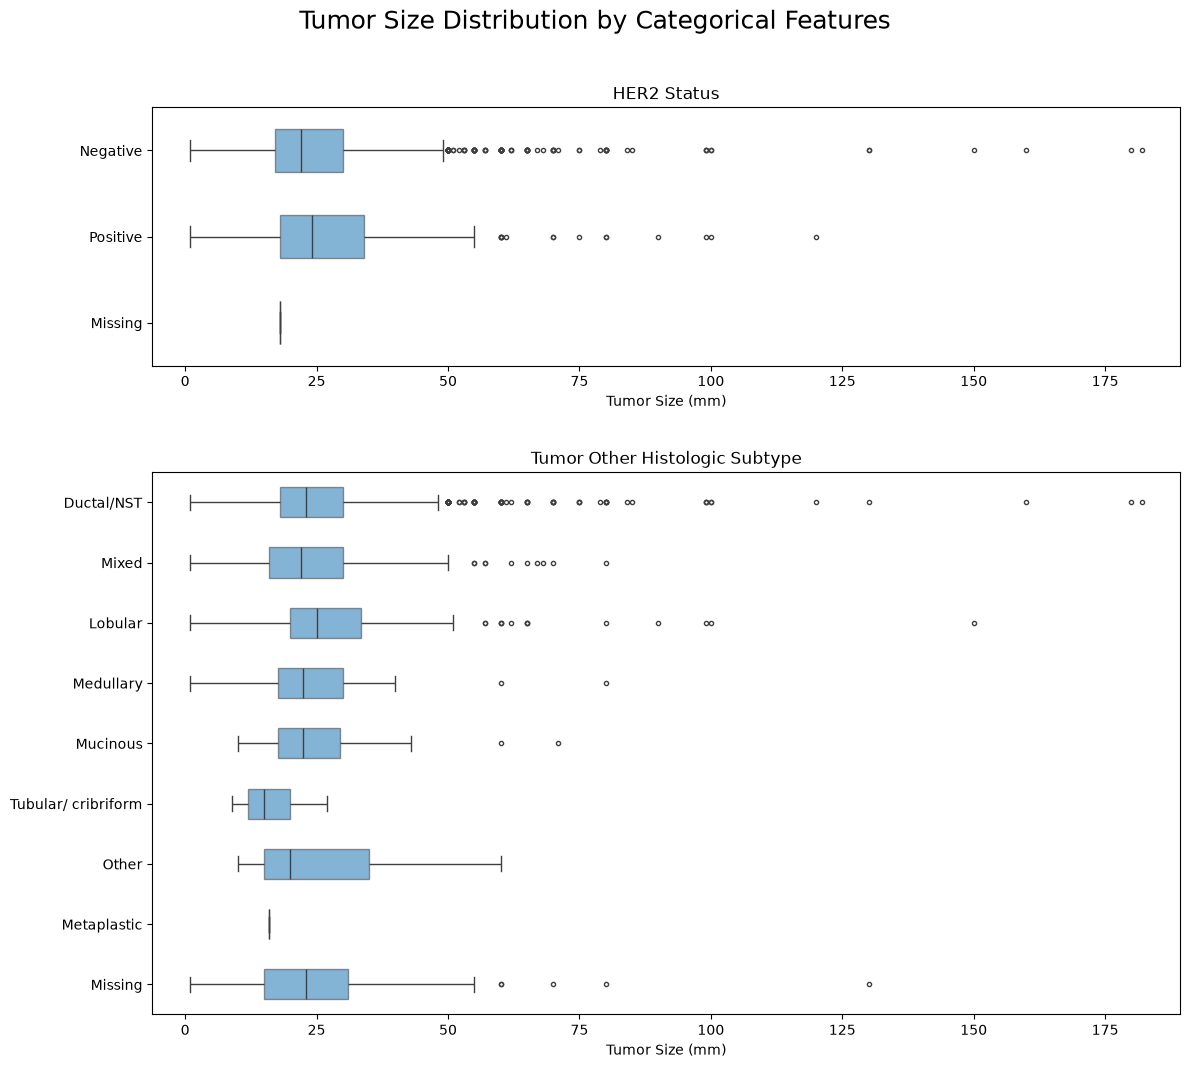

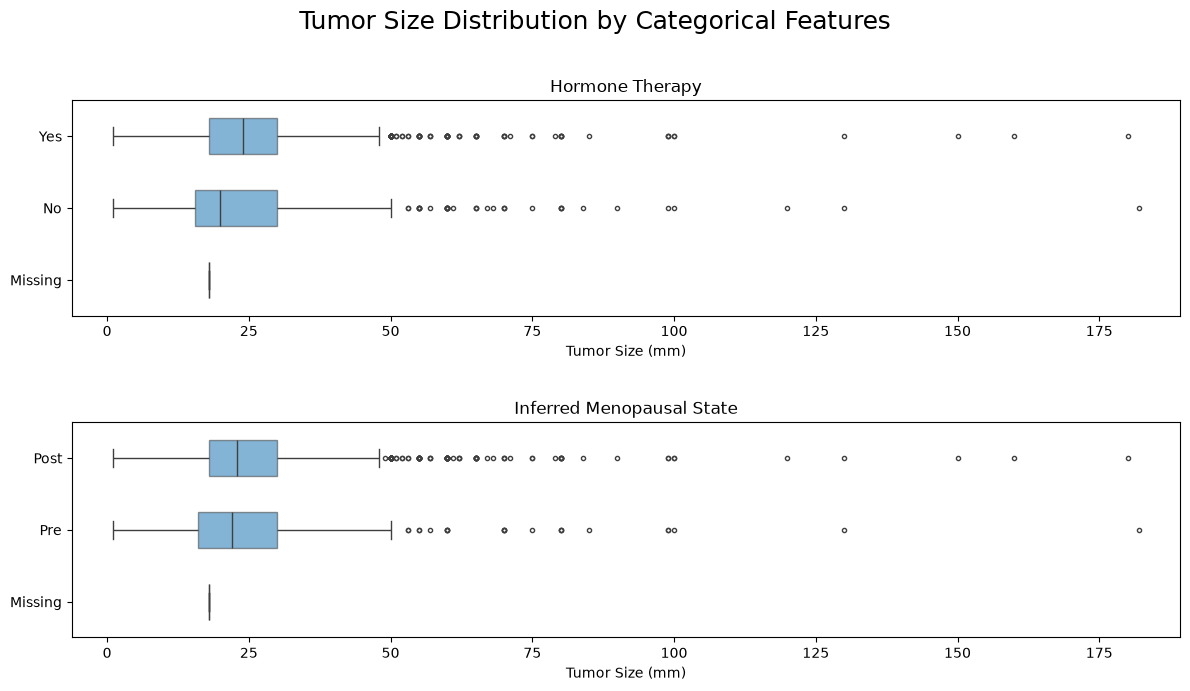

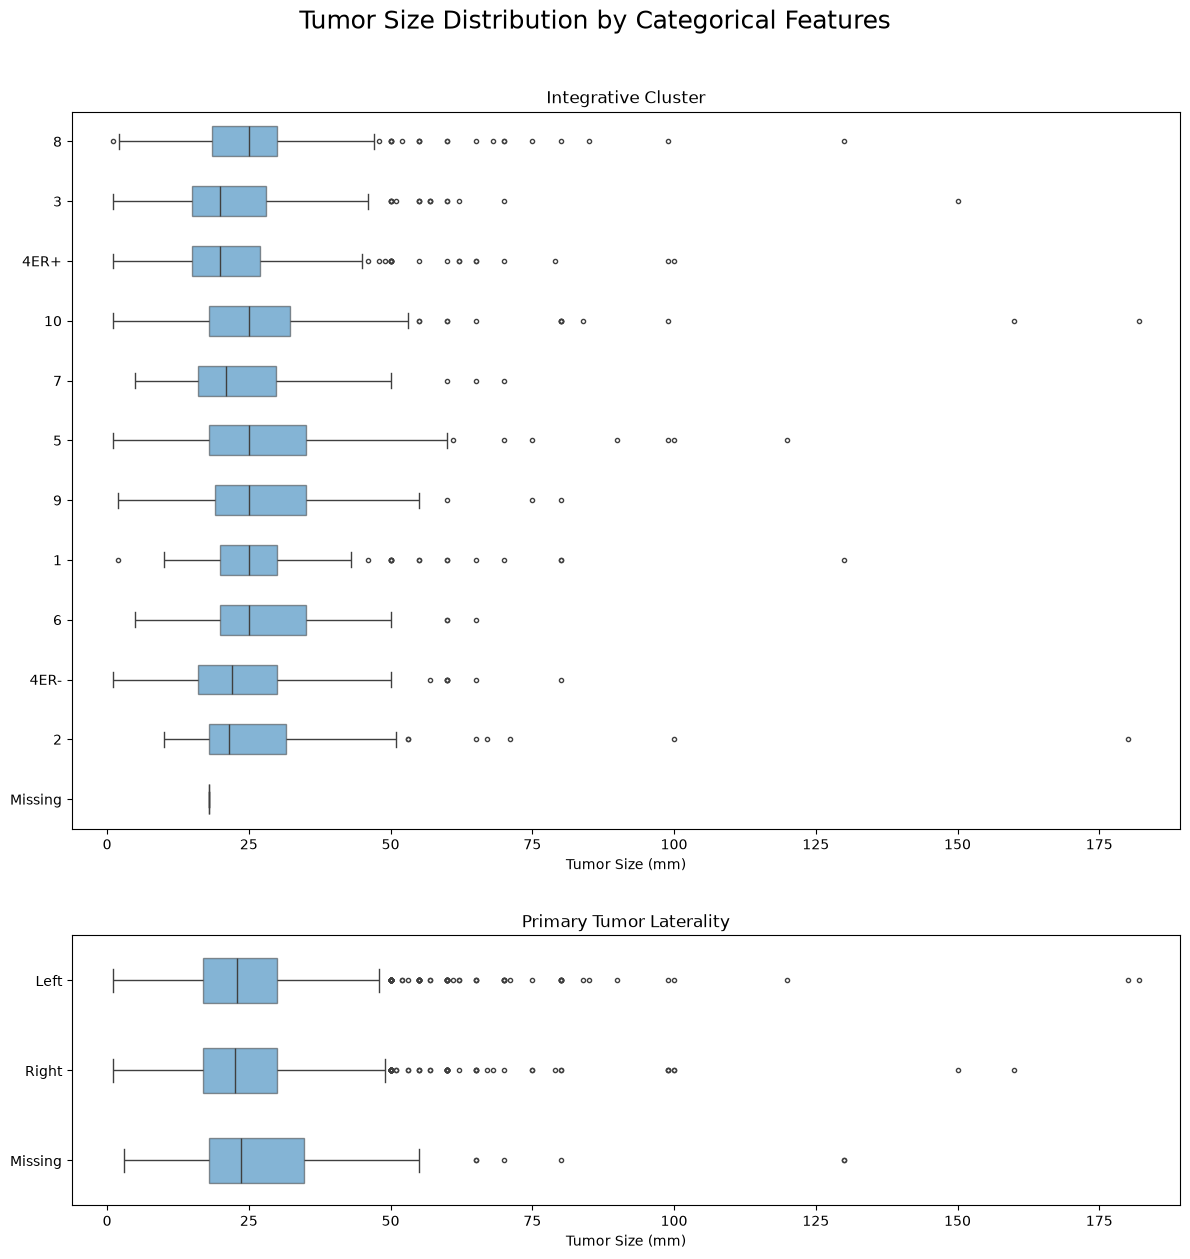

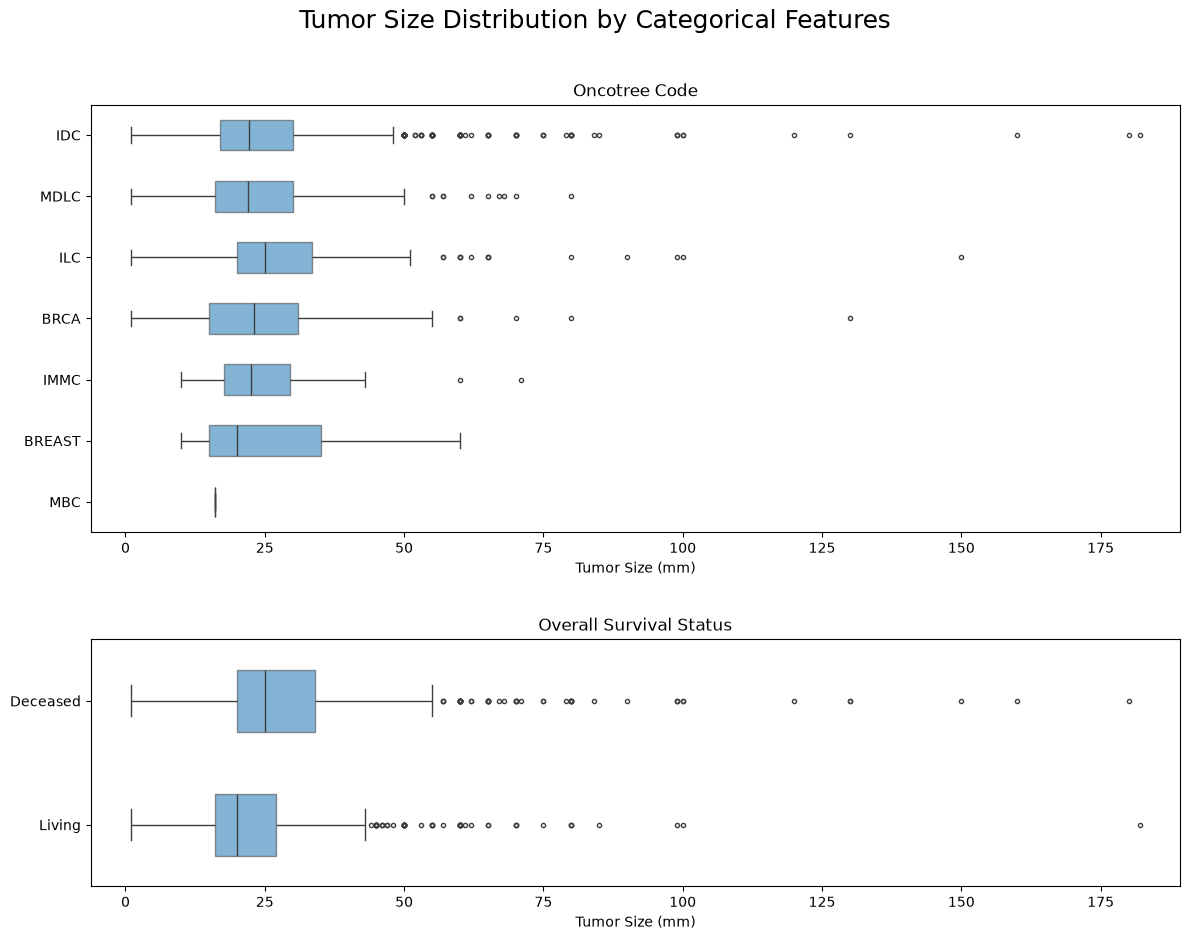

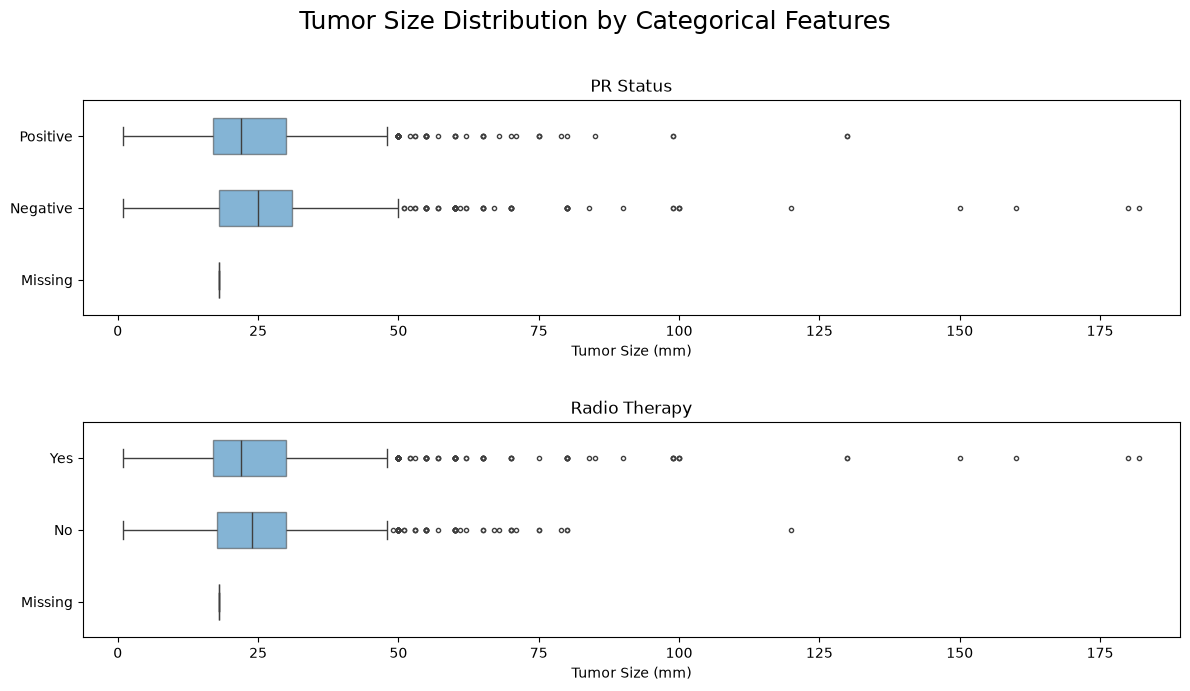

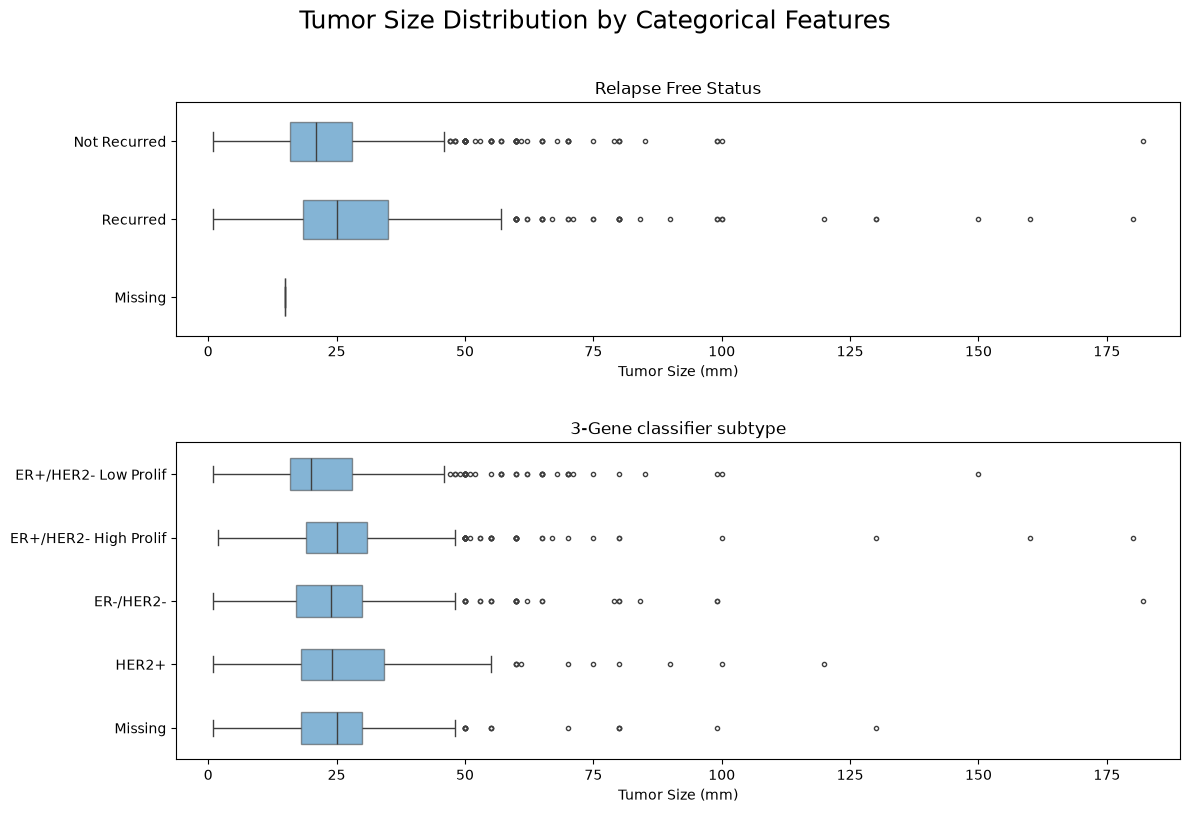

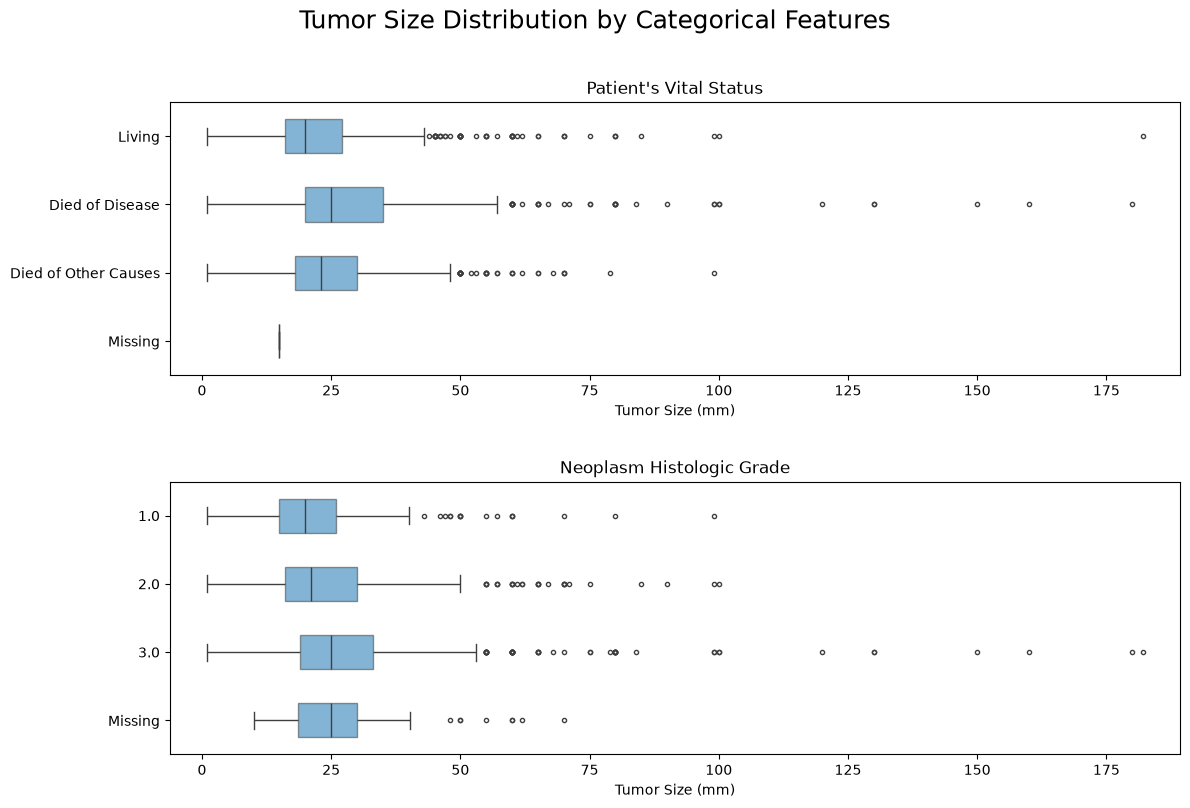

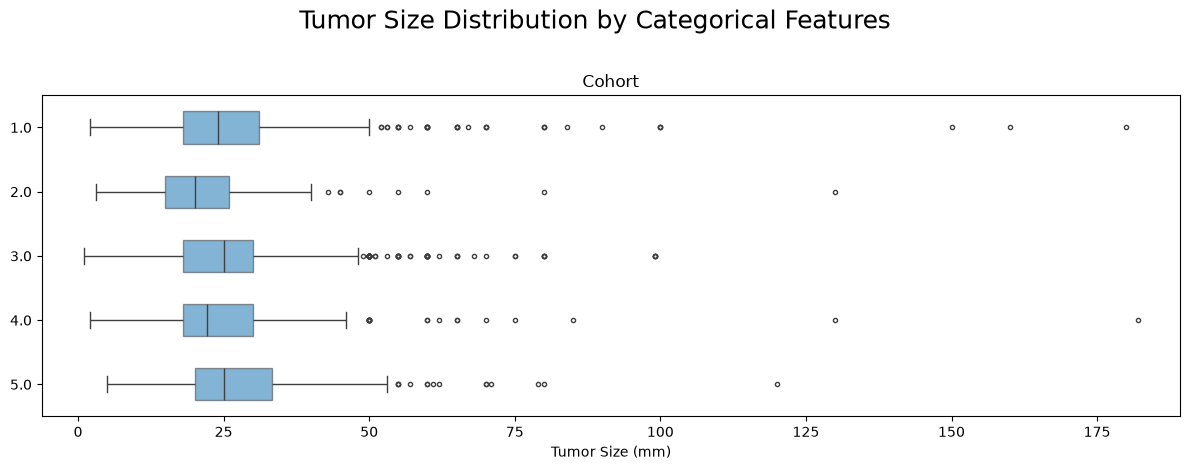

In [83]:
# Tumor size by categorical feature
import textwrap


# Two plots per figure leave enough room for the category names.
for start in range(0, len(categorical_cols), 2):
    columns = categorical_cols[start:start + 2]
    heights = [max(3.5, 1.5 + 0.65 * df_clean[col].nunique(dropna=False))
               for col in columns]
    fig, axes = plt.subplots(
        len(columns), 1, figsize=(12, sum(heights)), squeeze=False,
        gridspec_kw={'height_ratios': heights}
    )

    for ax, col in zip(axes.flatten(), columns):
        plot_data = df_clean[[col, 'Tumor Size']].dropna(subset=['Tumor Size']).copy()
        plot_data[col] = plot_data[col].astype('string').fillna('Missing')
        if col in categorical_numeric or col == 'Cohort':
            order = sorted([v for v in plot_data[col].unique() if v != 'Missing'],
                           key=float)
        else:
            order = plot_data[col].value_counts().index.drop('Missing', errors='ignore').tolist()
        if plot_data[col].eq('Missing').any():
            order.append('Missing')

        if not order:
            ax.set_title(col)
            ax.text(0.5, 0.5, 'No observed values', transform=ax.transAxes, ha='center')
            continue

        sns.boxplot(
            data=plot_data, x='Tumor Size', y=col, order=order,
            color='#1f77b4', saturation=1, width=0.5,
            linewidth=1, fliersize=3, boxprops={'alpha': 0.55}, ax=ax
        )
        ax.set_yticks(range(len(order)))
        ax.set_yticklabels([textwrap.fill(str(value), 34) for value in order], fontsize=10)
        ax.set_title(col, fontsize=12)
        ax.set_xlabel('Tumor Size (mm)')
        ax.set_ylabel('')
        limits = df_clean['Tumor Size'].dropna()
        if not limits.empty:
            margin = max((limits.max() - limits.min()) * 0.04, 1)
            ax.set_xlim(min(0, limits.min() - margin), limits.max() + margin)

    plt.suptitle('Tumor Size Distribution by Categorical Features', fontsize=18)
    plt.tight_layout(h_pad=3, rect=[0, 0, 1, 0.96])
    plt.show()


### Correlations and associations

**Spearman correlation** measures monotonic relationships between numerical variables using their ranks. Each coefficient uses patients with both values observed; IDs and cohort numbers are excluded. The notebook does not calculate hypothesis-test p-values or multiple-testing corrections. Correlations involving follow-up times are descriptive, not a censoring-aware survival analysis.

**Bias-corrected Cramér's V** measures association between two categorical variables on a 0–1 scale, without a sign. Missing values are excluded separately for each pair, rather than becoming a shared category. `pair_counts` shows the number of patients behind each coefficient. Pairwise exclusion avoids inventing values, but does not remove possible bias from systematic missingness.

For a categorical variable and tumour size, the matrix uses **eta (η)**, not eta squared. Its square, η², is the fraction of observed size variation between groups. The mixed matrix therefore contains different measures: compare them with care. Very strong categorical associations can indicate overlapping encodings rather than independent information. None of these measures establishes causality.


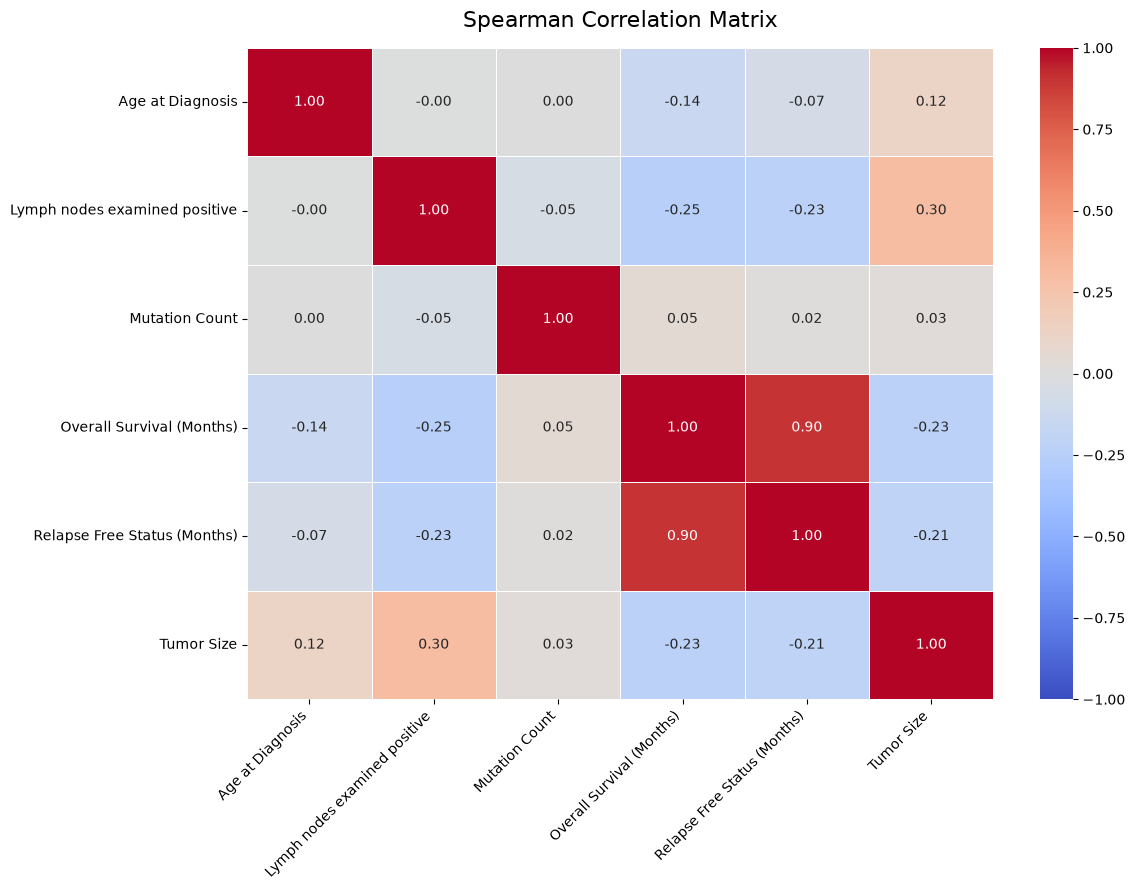

In [84]:
# Calculate Spearman correlation matrix
corr_matrix = df_clean[numeric_cols].corr(method='spearman')

# Plot heatmap
plt.figure(figsize=(12, 9))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title('Spearman Correlation Matrix', fontsize=16, pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

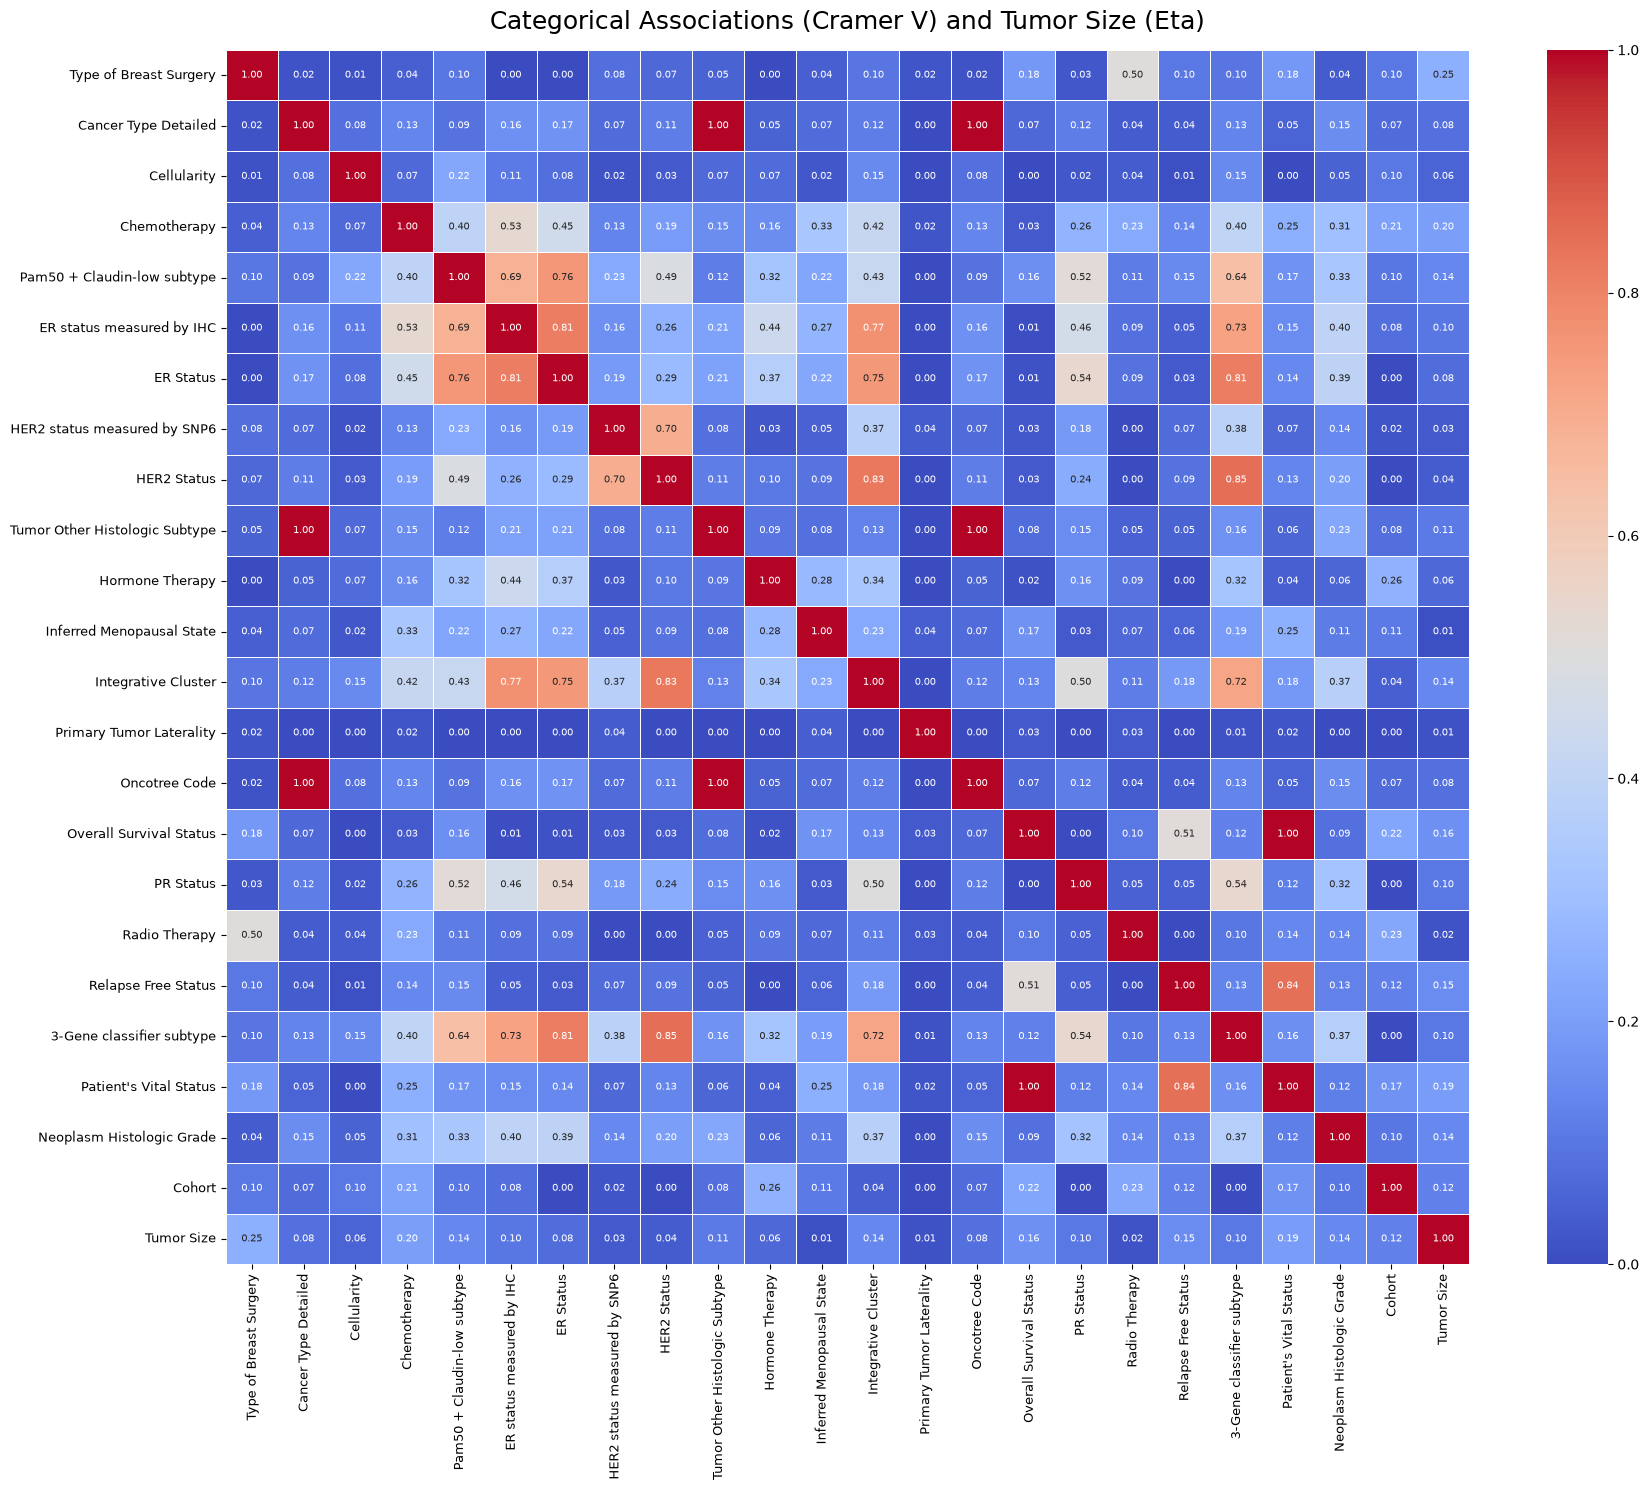

Number of observed patients for each association:


,Type of Breast Surgery,Cancer Type Detailed,Cellularity,Chemotherapy,Pam50 + Claudin-low subtype,ER status measured by IHC,ER Status,HER2 status measured by SNP6,HER2 Status,Tumor Other Histologic Subtype,...,Oncotree Code,Overall Survival Status,PR Status,Radio Therapy,Relapse Free Status,3-Gene classifier subtype,Patient's Vital Status,Neoplasm Histologic Grade,Cohort,Tumor Size
Type of Breast Surgery,1937,1937,1877,1937,1937,1902,1937,1937,1937,1899,...,1937,1937,1937,1937,1936,1728,1936,1859,1937,1937
Cancer Type Detailed,1937,1955,1894,1954,1954,1919,1955,1954,1954,1916,...,1955,1955,1954,1954,1954,1743,1954,1876,1955,1955
Cellularity,1877,1894,1894,1894,1894,1860,1894,1894,1894,1859,...,1894,1894,1894,1894,1893,1692,1893,1819,1894,1894
Chemotherapy,1937,1954,1894,1954,1954,1918,1954,1954,1954,1915,...,1954,1954,1954,1954,1953,1743,1953,1875,1954,1954
Pam50 + Claudin-low subtype,1937,1954,1894,1954,1954,1918,1954,1954,1954,1915,...,1954,1954,1954,1954,1953,1743,1953,1875,1954,1954
ER status measured by IHC,1902,1919,1860,1918,1918,1919,1919,1918,1918,1888,...,1919,1919,1918,1918,1918,1713,1918,1853,1919,1919
ER Status,1937,1955,1894,1954,1954,1919,1955,1954,1954,1916,...,1955,1955,1954,1954,1954,1743,1954,1876,1955,1955
HER2 status measured by SNP6,1937,1954,1894,1954,1954,1918,1954,1954,1954,1915,...,1954,1954,1954,1954,1953,1743,1953,1875,1954,1954
HER2 Status,1937,1954,1894,1954,1954,1918,1954,1954,1954,1915,...,1954,1954,1954,1954,1953,1743,1953,1875,1954,1954
Tumor Other Histologic Subtype,1899,1916,1859,1915,1915,1888,1916,1915,1915,1916,...,1916,1916,1915,1915,1915,1711,1915,1846,1916,1916


In [85]:
from scipy.stats import chi2_contingency

# Cramer's V: categorical vs categorical
def cramers_v(x, y):

    # Keep only patients with both variables observed.
    data = pd.DataFrame({'x': x, 'y': y}).dropna()
    table = pd.crosstab(data['x'], data['y'])

    if min(table.shape) < 2:
        return np.nan

    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()

    phi2 = chi2 / n
    r, k = table.shape

    phi2corr = max(0, phi2 - (k - 1) * (r - 1) / (n - 1))
    rcorr = r - (r - 1)**2 / (n - 1)
    kcorr = k - (k - 1)**2 / (n - 1)

    denominator = min(kcorr - 1, rcorr - 1)

    return np.sqrt(phi2corr / denominator) if denominator > 0 else np.nan


# Eta (not eta squared): categorical vs numerical
def correlation_ratio(categories, values):

    data = pd.DataFrame({
        'category': categories.astype('string'),
        'value': values
    }).dropna()

    if data.empty:
        return np.nan

    overall_mean = data['value'].mean()

    between_variance = sum(
        len(group) * (group.mean() - overall_mean)**2
        for _, group in data.groupby('category')['value']
    )

    total_variance = (
        (data['value'] - overall_mean)**2
    ).sum()

    return np.sqrt(between_variance / total_variance) if total_variance > 0 else np.nan


# Create association matrix
all_cols = categorical_cols + ['Tumor Size']

association_matrix = pd.DataFrame(
    index=all_cols,
    columns=all_cols,
    dtype=float
)

# Number of patients available for each pair of variables.
pair_counts = pd.DataFrame(0, index=all_cols, columns=all_cols)

for col1 in all_cols:
    for col2 in all_cols:

        pair_counts.loc[col1, col2] = (
            df_clean[[col1, col2]].notna().all(axis=1).sum()
        )

        if col1 == col2:
            association_matrix.loc[col1, col2] = 1.0

        elif col1 == 'Tumor Size':
            association_matrix.loc[col1, col2] = correlation_ratio(
                df_clean[col2], df_clean[col1]
            )

        elif col2 == 'Tumor Size':
            association_matrix.loc[col1, col2] = correlation_ratio(
                df_clean[col1], df_clean[col2]
            )

        else:
            association_matrix.loc[col1, col2] = cramers_v(
                df_clean[col1], df_clean[col2]
            )


# Plot heatmap
plt.figure(figsize=(18, 15))

sns.heatmap(
    association_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=0,
    vmax=1,
    linewidths=0.5,
    annot_kws={'size': 7}
)

plt.title(
    'Categorical Associations (Cramer V) and Tumor Size (Eta)',
    fontsize=18,
    pad=15
)

plt.xticks(rotation=90, fontsize=9)
plt.yticks(rotation=0, fontsize=9)

plt.tight_layout()
plt.show()

# Report the available sample size so that associations are not read without context.
print('Number of observed patients for each association:')
display(pair_counts)


### Regression findings

- Spearman correlations with size are **0.12 for age**, **0.30 for positive nodes** and **0.03 for mutation count**. Positive nodes show the clearest monotonic trend of these three variables; individual correlations are not estimates of model accuracy.


## 3. EDA for classification

The continuous regression target is `Tumor Size`. Classification uses **≤20 mm** and **>20 mm**, based on a size boundary described by the [National Cancer Institute](https://www.cancer.gov/types/breast/hp/breast-treatment-pdq). This is not a complete T-category assignment, clinical stage or risk score.

Class counts show imbalance. The predictor boxplots and group medians describe differences and overlap, not validated classification accuracy. Observed-value counts differ between predictors because missing values remain unfilled. `df_class` is a copy: the category is not added to `df_clean`. Neither size nor its derived category may be included among the classifier inputs.


### Class balance and selected predictors


,Patients,Percentage (%)
Size Category,,
≤20 mm,853,43.63
>20 mm,1102,56.37


Age at Diagnosis         Lymph nodes examined positive         \
                         count  median                         count median   
Size Category                                                                 
>20 mm                    1102  63.655                          1063    1.0   
≤20 mm                     853  60.330                           822    0.0   

              Mutation Count         
                       count median  
Size Category                        
>20 mm                  1041    5.0  
≤20 mm                   799    5.0

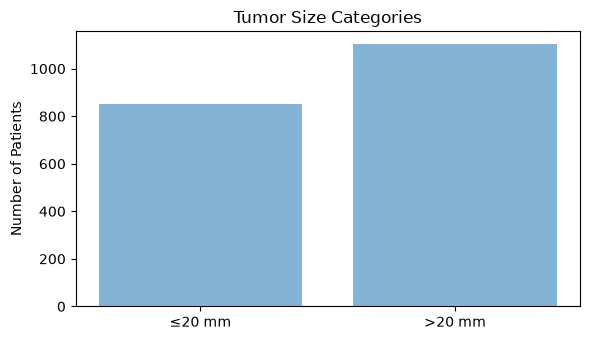

In [86]:
df_class = df_clean.copy()
class_order = ['≤20 mm', '>20 mm']
df_class['Size Category'] = np.where(
    df_class['Tumor Size'] <= 20, class_order[0], class_order[1]
)

class_counts = df_class['Size Category'].value_counts().reindex(class_order)
class_summary = pd.DataFrame({
    'Patients': class_counts,
    'Percentage (%)': class_counts / len(df_class) * 100
})
display(class_summary.round(2))

display(df_class.groupby('Size Category')[class_features].agg(['count', 'median']))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(class_order, class_counts.values, color='#1f77b4', alpha=0.55)
ax.set_title('Tumor Size Categories')
ax.set_ylabel('Number of Patients')
plt.tight_layout()
plt.show()


### Numerical boxplots by tumour size class

Each panel compares a numerical variable between the **≤20 mm** and **>20 mm** classes. These vertical boxplots complement the full-sample boxplots in section 1 by showing the distribution of each variable within each class. Missing measurements are omitted from their respective boxes.

The tumour size panel shows the class split by construction: tumour size defines the label and cannot be used as a classifier input. Follow-up variables are shown for descriptive purposes only.


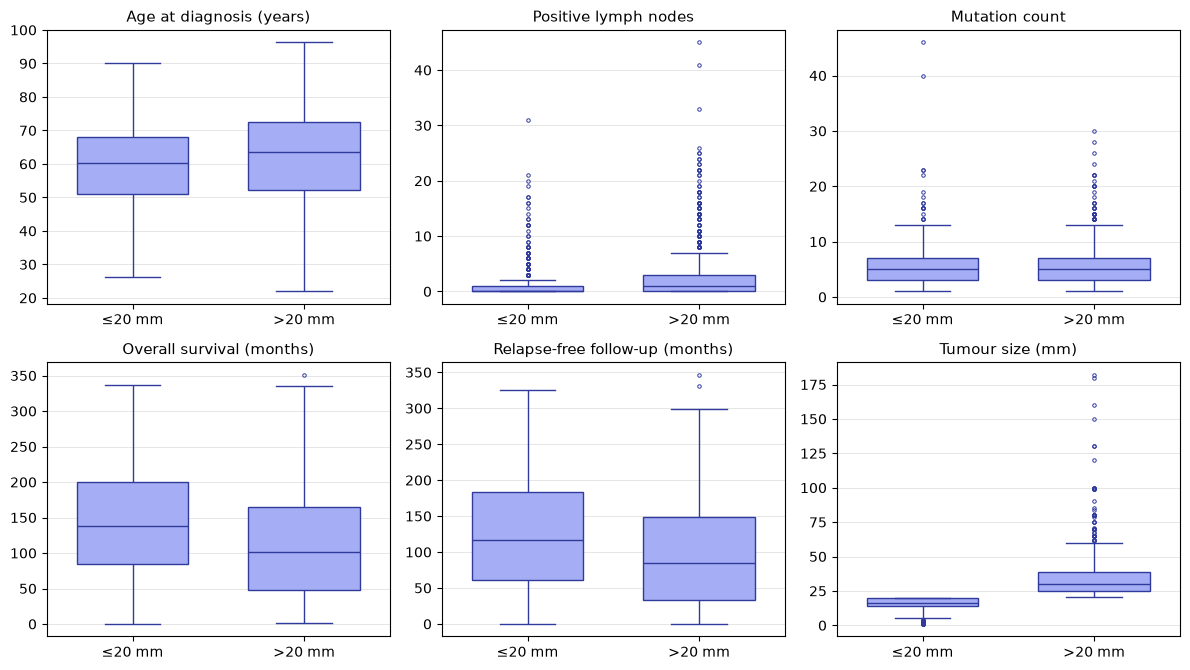

In [87]:
# Use a separate dataframe so the existing analysis is unaffected.
boxplot_data = df_clean.dropna(subset=['Tumor Size']).copy()
boxplot_class_order = ['≤20 mm', '>20 mm']
boxplot_data['Size Category'] = np.where(
    boxplot_data['Tumor Size'] <= 20, boxplot_class_order[0], boxplot_class_order[1]
)

# Compare all numerical variables in the same class order.
box_titles = {
    'Age at Diagnosis': 'Age at diagnosis (years)',
    'Lymph nodes examined positive': 'Positive lymph nodes',
    'Mutation Count': 'Mutation count',
    'Overall Survival (Months)': 'Overall survival (months)',
    'Relapse Free Status (Months)': 'Relapse-free follow-up (months)',
    'Tumor Size': 'Tumour size (mm)'
}

ncols = 3
nrows = (len(numeric_cols) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(12, 3.4 * nrows), squeeze=False)
axes = axes.flatten()

for ax, col in zip(axes, numeric_cols):
    sns.boxplot(
        data=boxplot_data, x='Size Category', y=col, order=boxplot_class_order,
        color='#A5AEF4', saturation=1, width=0.65, linewidth=1, ax=ax,
        boxprops={'edgecolor': '#303A9C'},
        medianprops={'color': '#303A9C'},
        whiskerprops={'color': '#303A9C'},
        capprops={'color': '#303A9C'},
        flierprops={'marker': 'o', 'markersize': 2.5,
                    'markerfacecolor': 'none', 'markeredgecolor': '#303A9C',
                    'markeredgewidth': 0.7}
    )
    ax.set_title(box_titles.get(col, col), fontsize=11)
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.set_axisbelow(True)
    ax.grid(axis='y', color='0.9', linewidth=0.7)

for ax in axes[len(numeric_cols):]:
    ax.remove()

plt.tight_layout()
plt.show()


### Histological grade within each size class

The numerical comparisons above do not cover categorical biomarkers or grade. This table adds one categorical comparison without another plot. Each row sums to **100% of that size class**, including patients with missing grade. This denominator makes the two classes comparable even when their sizes differ.

A larger proportion of grade 3 in one class is an association in this sample, not a causal explanation or a validated predictor. Missing-grade percentages also need checking: different coverage between classes can influence the comparison.


In [88]:
# Keep all patients in the denominator, including those with unknown grade.
grade_labels = df_class['Neoplasm Histologic Grade'].astype('string').fillna('Missing')
grade_labels = grade_labels.replace({'1.0': 'Grade 1', '2.0': 'Grade 2', '3.0': 'Grade 3'})
grade_counts = pd.crosstab(df_class['Size Category'], grade_labels).reindex(class_order)
grade_percent = grade_counts.div(grade_counts.sum(axis=1), axis=0) * 100
display(grade_percent.round(2))


Neoplasm Histologic Grade,Grade 1,Grade 2,Grade 3,Missing
Size Category,,,,
≤20 mm,12.31,43.49,40.80,3.40
>20 mm,5.63,35.57,54.26,4.54


### Classification findings

- The classes contain **853 patients with size ≤20 mm** and **1102 with size >20 mm**. Class balance is relatively even, but it does not guarantee good predictive performance.
- Grade 3 represents **40.8%** of the ≤20 mm class and **54.3%** of the >20 mm class. The class distributions differ, but overlap remains and this observation is not causal.


## 4. Next modelling steps

The findings above refer to this execution and should be updated if the data or cleaning rules change.

- The proposed main inputs exclude the target, its derived label, identifiers, treatment and follow-up. Check the timing of candidate clinical measurements and review overlapping histology and molecular encodings on training data.
- Reserve the test set before further outcome-guided choices. Fit imputation, encoding and scaling within training folds. Missing categorical values must not be assumed to mean a negative result. Clinical usefulness requires a separate validation design; this EDA alone does not demonstrate it.
